<a href="https://colab.research.google.com/github/AkariYM/Mapa_Astroshield/blob/main/AstroShield_Map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AstroShield — Evolucionar una constelación inteligente

Cuaderno de Google Colab con el algoritmo evolutivo, las restricciones espaciales, las pruebas, el análisis y el **centro de mando 2D/3D** estilo Cyberpunk.

| Sección | Qué contiene | Entregable |
|---|---|---|
| 1 | Modelo y supuestos | 1 |
| 2 | Paquete `astroshield` (módulos) y pruebas automáticas | 2 |
| 3 | Etapa 1 y Etapa 2 (sin y con restricciones) | 2 |
| 4 | Pruebas T1 a T7 y pruebas propias A, B y C | 3 |
| 5 | Cambio de condiciones | 3 |
| 6 | Análisis de resultados | 4 |
| 7 | Centro de mando 2D y 3D | 5 |
| 8 | Exportar resultados | 6 |

## 1. Modelo y supuestos

Estas son las decisiones que convierten el escenario en un problema computacional. Si cambias alguna, cambia aquí y en tu documento de definición.

- **Representación:** una configuración es una matriz de 8 filas (satélites) × 2 columnas (latitud, longitud en grados). Cada satélite se modela por su punto subsatelital sobre una esfera de radio 6 371 km. La altitud solo se usa para dibujar.
- **Cobertura de un punto:** un punto de la Tierra está cubierto si algún satélite está a una distancia sobre la esfera menor o igual al **radio del sensor** (supuesto: 1 000 km, parámetro `radio_sensor_km`).
- **Cobertura de una región:** cada región es un disco de 300 km de radio. Se muestrea con 150 puntos repartidos de forma uniforme y determinista. La *cobertura* de la región es la fracción de esos puntos cubiertos. La región se considera **cubierta** si la cobertura es al menos 95 % (`umbral_cubierta`).
- **Prioridades:** Alta = 3, Media = 2, Normal = 1 (pesos).
- **Calidad (fitness):** promedio ponderado por prioridad de `0.8 · cobertura + 0.2 · doble cobertura`, donde la doble cobertura es la fracción de puntos vistos por 2 o más satélites. Va de 0 a 1. La parte de doble cobertura da un uso a los satélites que sobran cuando ya se cubrieron las seis regiones.
- **Validez:** una configuración es **inválida** si algún satélite queda dentro de una zona restringida o de una posición ocupada (distancia angular al centro menor que el radio de la zona). La violación se mide como la suma de `(radio − distancia) / radio` sobre los pares satélite-zona que se incumplen.
- **Manejo de restricciones:** regla de factibilidad en el torneo (una configuración válida siempre le gana a una inválida; entre válidas gana la de mayor calidad; entre inválidas gana la de menor violación). La población inicial se genera por muestreo con rechazo para que parta válida. Una puntuación alta nunca hace válida a una configuración que incumple.
- **Algoritmo:** algoritmo genético con selección por torneo, cruce que toma 8 satélites al azar de la unión de los dos padres (los satélites son un conjunto, no una lista ordenada), mutación gaussiana sobre la esfera con paso decreciente, reinicio aleatorio ocasional y elitismo.
- **Parada:** número máximo de generaciones o paciencia (generaciones seguidas sin mejora). Dejar de mejorar **no** prueba que se halló el óptimo; por eso se compara con una cota teórica y con búsqueda aleatoria.
- **Simplificaciones declaradas:** satélites estáticos (no se simula la mecánica orbital), cobertura circular, sin nubosidad ni horarios de paso.

In [1]:
import os
if not os.path.isdir("astroshield") and os.path.isdir("../astroshield"):
    os.chdir("..")                      # si lo abres desde la carpeta notebooks/ del repositorio
os.makedirs("astroshield", exist_ok=True); os.makedirs("tests", exist_ok=True); os.makedirs("resultados", exist_ok=True)

In [2]:
%%writefile astroshield/__init__.py
"""AstroShield: constelación de satélites diseñada con un algoritmo evolutivo."""

__version__ = "1.0.0"

Writing astroshield/__init__.py


In [3]:
%%writefile astroshield/geometria.py
"""Geometría sobre la esfera terrestre: vectores, distancias, puntos y destinos."""
import numpy as np

R_TIERRA = 6371.0          # km

def a_vec(lat, lon):
    lat = np.radians(lat); lon = np.radians(lon)
    return np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], axis=-1)

def dist_deg(lat1, lon1, lat2, lon2):
    c = np.sum(a_vec(lat1, lon1) * a_vec(lat2, lon2), axis=-1)
    return np.degrees(np.arccos(np.clip(c, -1, 1)))

def dist_km(lat1, lon1, lat2, lon2):
    return np.radians(dist_deg(lat1, lon1, lat2, lon2)) * R_TIERRA

def destino(lat, lon, rumbo_deg, dist_deg_):
    """Punto al que se llega desde (lat, lon) avanzando dist_deg_ grados en el rumbo dado."""
    la1, lo1, br, d = map(np.radians, (lat, lon, rumbo_deg, dist_deg_))
    la2 = np.arcsin(np.sin(la1) * np.cos(d) + np.cos(la1) * np.sin(d) * np.cos(br))
    lo2 = lo1 + np.arctan2(np.sin(br) * np.sin(d) * np.cos(la1), np.cos(d) - np.sin(la1) * np.sin(la2))
    return np.degrees(la2), (np.degrees(lo2) + 180) % 360 - 180

def punto_aleatorio(rng, n):
    """n puntos uniformes sobre la esfera, como arreglo (n, 2) de [lat, lon]."""
    lat = np.degrees(np.arcsin(rng.uniform(-1, 1, n)))
    lon = rng.uniform(-180, 180, n)
    return np.stack([lat, lon], axis=-1)

def puntos_disco(lat, lon, radio_km, n):
    """n puntos uniformes y deterministas (espiral de girasol) dentro de un disco sobre la esfera."""
    i = np.arange(n)
    r_deg = np.degrees((radio_km / R_TIERRA) * np.sqrt((i + 0.5) / n))
    ang = i * 137.50776405
    la, lo = destino(lat, lon, ang, r_deg)
    return a_vec(la, lo)

Writing astroshield/geometria.py


In [4]:
%%writefile astroshield/escenario.py
"""Escenario del problema: regiones, zonas restringidas, posiciones ocupadas y supuestos del modelo."""
from dataclasses import dataclass, field

@dataclass(frozen=True)
class Region:
    nombre: str
    lat: float
    lon: float
    prioridad: str          # "Alta", "Media" o "Normal"

@dataclass(frozen=True)
class Zona:
    nombre: str
    lat: float
    lon: float
    radio_deg: float        # radio angular sobre la esfera
    tipo: str               # "desechos" u "ocupada"

@dataclass
class Escenario:
    regiones: tuple
    zonas: tuple = ()
    n_sat: int = 8
    radio_region_km: float = 300.0
    radio_sensor_km: float = 1000.0     # supuesto del modelo
    altitud_km: float = 800.0           # solo para dibujar
    pesos: dict = field(default_factory=lambda: {"Alta": 3.0, "Media": 2.0, "Normal": 1.0})
    peso_redundancia: float = 0.2
    umbral_cubierta: float = 0.95
    n_puntos: int = 150

REGIONES = (
    Region("Península de Yucatán", 20.5, -89.0, "Alta"),
    Region("Amazonía brasileña", -3.5, -62.0, "Alta"),
    Region("California", 36.8, -119.4, "Media"),
    Region("Sahel", 15.0, 0.0, "Media"),
    Region("Japón", 36.0, 138.0, "Media"),
    Region("Interior de Australia", -25.0, 133.0, "Normal"),
)
ZONAS_DESECHOS = (
    Zona("Desechos Atlántico Norte", 45.0, -35.0, 12.0, "desechos"),
    Zona("Desechos Pacífico Sur", -30.0, -120.0, 10.0, "desechos"),
    Zona("Desechos Polar Norte", 78.0, 30.0, 8.0, "desechos"),
)
OCUPADAS = (
    Zona("Objeto A", 10.0, 45.0, 5.0, "ocupada"),
    Zona("Objeto B", -15.0, 110.0, 5.0, "ocupada"),
)
ESC_ETAPA1 = Escenario(regiones=REGIONES)                                   # sin restricciones
ESC_ETAPA2 = Escenario(regiones=REGIONES, zonas=ZONAS_DESECHOS + OCUPADAS)  # con restricciones

Writing astroshield/escenario.py


In [5]:
%%writefile astroshield/evaluacion.py
"""Evaluación de configuraciones: cobertura, calidad F, validez y cota teórica."""
import numpy as np

from .geometria import R_TIERRA, a_vec, destino, dist_km, punto_aleatorio, puntos_disco


class Evaluador:
    """Evalúa poblaciones de configuraciones de forma vectorizada para un escenario dado."""
    def __init__(self, esc):
        self.esc = esc
        self.pts = np.stack([puntos_disco(r.lat, r.lon, esc.radio_region_km, esc.n_puntos) for r in esc.regiones])
        self.w = np.array([esc.pesos[r.prioridad] for r in esc.regiones], float)
        self.cos_sensor = np.cos(esc.radio_sensor_km / R_TIERRA)
        if esc.zonas:
            self.zv = a_vec(np.array([z.lat for z in esc.zonas]), np.array([z.lon for z in esc.zonas]))
        else:
            self.zv = np.zeros((0, 3))
        self.zr = np.array([z.radio_deg for z in esc.zonas], float)
        self.n_eval = 0

    def violacion_puntos(self, ll):
        """Violación de restricciones de puntos sueltos, forma (..., 2). 0 significa válido."""
        if len(self.zr) == 0:
            return np.zeros(ll.shape[:-1])
        v = a_vec(ll[..., 0], ll[..., 1])
        d = np.degrees(np.arccos(np.clip(np.einsum('...k,zk->...z', v, self.zv), -1, 1)))
        return np.clip((self.zr - d) / self.zr, 0, None).sum(-1)

    def evaluar(self, pop):
        """pop: (P, S, 2). Devuelve F (calidad), V (violación), cov y cov2 por región."""
        pop = np.asarray(pop, float)
        self.n_eval += pop.shape[0]
        sv = a_vec(pop[..., 0], pop[..., 1])                          # (P, S, 3)
        cerca = np.einsum('psk,rnk->psrn', sv, self.pts) >= self.cos_sensor
        cnt = cerca.sum(axis=1)                                        # (P, R, N)
        cov = (cnt >= 1).mean(-1)
        cov2 = (cnt >= 2).mean(-1)
        a = self.esc.peso_redundancia
        puntaje = (1 - a) * cov + a * cov2
        F = (puntaje * self.w).sum(-1) / self.w.sum()
        V = self.violacion_puntos(pop).sum(-1)
        return {"F": F, "V": V, "cov": cov, "cov2": cov2}

    def muestrear_factibles(self, n, rng, intentos=200):
        ll = punto_aleatorio(rng, n)
        for _ in range(intentos):
            mal = self.violacion_puntos(ll) > 0
            if not mal.any():
                break
            ll[mal] = punto_aleatorio(rng, int(mal.sum()))
        return ll

def clave(r):
    """Orden de preferencia (menor es mejor): válidas por calidad; inválidas por violación, siempre peores."""
    return np.where(r["V"] > 0, 1e3 + r["V"], -r["F"])

def cota_superior(esc):
    """Cota superior de F cuando ningún satélite puede ver puntos de dos regiones a la vez
    (separación entre centros mayor que 2·(radio del sensor + radio de región)).
    Ganancia de un 1.er satélite en una región: (1-a)*w. Del 2.º: a*w. Se toman las n_sat mejores ganancias."""
    a = esc.peso_redundancia
    w = [esc.pesos[r.prioridad] for r in esc.regiones]
    ganancias = sorted([(1 - a) * x for x in w] + [a * x for x in w], reverse=True)[:esc.n_sat]
    return sum(ganancias) / sum(w)

def separacion_minima_regiones_km(esc):
    d = [dist_km(a.lat, a.lon, b.lat, b.lon) for i, a in enumerate(esc.regiones) for b in esc.regiones[i + 1:]]
    return float(min(d))

def region_alcanzable(ev, r, n=400):
    """¿Existe una posición válida desde la que un satélite cubra por completo el disco de la región?"""
    esc = ev.esc
    alcance = esc.radio_sensor_km - esc.radio_region_km
    if alcance <= 0:
        return False
    pts = [np.array([[r.lat, r.lon]])]
    i = np.arange(n)
    la, lo = destino(r.lat, r.lon, i * 137.50776405, np.degrees(alcance / R_TIERRA) * np.sqrt((i + 0.5) / n))
    pts.append(np.stack([la, lo], -1))
    ll = np.concatenate(pts)
    return bool((ev.violacion_puntos(ll) == 0).any())

Writing astroshield/evaluacion.py


In [6]:
%%writefile astroshield/algoritmo.py
"""Algoritmo evolutivo (algoritmo genético) y línea base de búsqueda aleatoria."""
from dataclasses import dataclass

import numpy as np
import pandas as pd

from .evaluacion import clave
from .geometria import destino


@dataclass
class ParamsGA:
    pob: int = 200            # tamaño de la población
    gens: int = 200           # generaciones máximas
    torneo: int = 3           # tamaño del torneo
    p_cx: float = 0.9         # probabilidad de cruce
    p_mut: float = 0.20       # probabilidad de mutar cada satélite
    p_reset: float = 0.05     # probabilidad de reubicar un satélite al azar
    sigma0: float = 10.0      # paso inicial de mutación (grados)
    sigma_min: float = 0.5    # paso final de mutación (grados)
    elite: int = 4            # individuos que pasan intactos
    paciencia: int = 60       # generaciones sin mejora para detener (None = no detener)
    tol: float = 1e-4         # mejora mínima que cuenta

def _descendencia(ev, pop, key, n, sigma, p, rng):
    P, S, _ = pop.shape
    def torneo(m):
        idx = rng.integers(0, P, (m, p.torneo))
        return idx[np.arange(m), np.argmin(key[idx], axis=1)]
    pa, pb = pop[torneo(n)], pop[torneo(n)]
    union = np.concatenate([pa, pb], axis=1)                            # (n, 2S, 2)
    orden = np.argsort(rng.random((n, 2 * S)), axis=1)[:, :S]
    hijo = np.take_along_axis(union, orden[..., None], axis=1)
    sin_cx = rng.random(n) > p.p_cx
    hijo[sin_cx] = pa[sin_cx]
    m = rng.random((n, S)) < p.p_mut                                     # mutación gaussiana en la esfera
    if m.any():
        rumbo = rng.uniform(0, 360, (n, S)); d = np.abs(rng.normal(0, sigma, (n, S)))
        la, lo = destino(hijo[..., 0], hijo[..., 1], rumbo, d)
        hijo[..., 0] = np.where(m, la, hijo[..., 0]); hijo[..., 1] = np.where(m, lo, hijo[..., 1])
    rs = rng.random((n, S)) < p.p_reset                                  # reubicación aleatoria
    if rs.any():
        hijo[rs] = ev.muestrear_factibles(int(rs.sum()), rng)
    return hijo

def ejecutar_ga(ev, p, seed, pob_inicial=None):
    rng = np.random.default_rng(seed)
    S = ev.esc.n_sat
    if pob_inicial is None:
        pop = ev.muestrear_factibles(p.pob * S, rng).reshape(p.pob, S, 2)
    else:
        pop = np.array(pob_inicial, float)
    ev.n_eval = 0
    r = ev.evaluar(pop); key = clave(r)
    hist, mejor_prev, sin_mejora, parada = [], np.inf, 0, "generaciones máximas"
    tray, cov_tray = [], []
    inicial = pop[np.argmin(key)].copy()
    for g in range(p.gens + 1):
        i = int(np.argmin(key))
        hist.append(dict(gen=g, mejor_F=r["F"][i], mejor_V=r["V"][i], media_F=r["F"].mean(), peor_F=r["F"].min(),
                         frac_validas=(r["V"] == 0).mean(), regiones_cubiertas=int((r["cov"][i] >= ev.esc.umbral_cubierta).sum()),
                         evaluaciones=ev.n_eval))
        tray.append(pop[i].copy()); cov_tray.append(r["cov"][i].copy())
        if key[i] < mejor_prev - p.tol:
            mejor_prev, sin_mejora = key[i], 0
        else:
            sin_mejora += 1
        if p.paciencia and sin_mejora >= p.paciencia:
            parada = f"sin mejora durante {p.paciencia} generaciones"
            break
        if g == p.gens:
            break
        sigma = p.sigma_min + (p.sigma0 - p.sigma_min) * (1 - g / p.gens) ** 2
        elite_idx = np.argsort(key)[:p.elite]
        hijos = _descendencia(ev, pop, key, p.pob - p.elite, sigma, p, rng)
        rh = ev.evaluar(hijos)
        pop = np.concatenate([pop[elite_idx], hijos])
        r = {k: np.concatenate([r[k][elite_idx], rh[k]]) for k in r}
        key = clave(r)
    i = int(np.argmin(key))
    return dict(config=pop[i].copy(), F=float(r["F"][i]), V=float(r["V"][i]), cov=r["cov"][i].copy(), cov2=r["cov2"][i].copy(),
                valida=bool(r["V"][i] == 0), hist=pd.DataFrame(hist), inicial=inicial, seed=seed,
                gens_ejecutadas=len(hist) - 1, parada=parada, evaluaciones=ev.n_eval, pob_final=pop,
                tray=np.array(tray), cov_tray=np.array(cov_tray))

def busqueda_aleatoria(ev, n_eval, seed, lote=2000):
    """Línea base: muestrea configuraciones válidas al azar con el mismo presupuesto de evaluaciones."""
    rng = np.random.default_rng(seed); S = ev.esc.n_sat
    mejor = None; hecho = 0
    while hecho < n_eval:
        m = min(lote, n_eval - hecho)
        pop = ev.muestrear_factibles(m * S, rng).reshape(m, S, 2)
        r = ev.evaluar(pop); k = clave(r); i = int(np.argmin(k))
        if mejor is None or k[i] < mejor[0]:
            mejor = (k[i], pop[i].copy(), r["F"][i], r["V"][i], r["cov"][i].copy())
        hecho += m
    return dict(config=mejor[1], F=float(mejor[2]), V=float(mejor[3]), cov=mejor[4], valida=bool(mejor[3] == 0), evaluaciones=n_eval)

Writing astroshield/algoritmo.py


In [7]:
%%writefile astroshield/analisis.py
"""Funciones de apoyo para las pruebas y el análisis: tablas, márgenes, cambios de condiciones."""
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

from .algoritmo import ejecutar_ga
from .evaluacion import Evaluador
from .geometria import destino, dist_deg, dist_km, punto_aleatorio


def tabla_regiones(res, ev):
    """Cobertura de cada región para el resultado `res` evaluado con `ev`."""
    esc = ev.esc
    c = res["config"]
    filas = []
    for k, r in enumerate(esc.regiones):
        d = dist_km(r.lat, r.lon, c[:, 0], c[:, 1])
        filas.append({"Región": r.nombre, "Prioridad": r.prioridad, "Cobertura (%)": 100 * res["cov"][k],
                      "Doble cobertura (%)": 100 * res["cov2"][k],
                      "¿Cubierta?": "Sí" if res["cov"][k] >= esc.umbral_cubierta else "No",
                      "Satélite más cercano (km)": d.min(),
                      "Satélites a ≤ radio del sensor": int((d <= esc.radio_sensor_km).sum())})
    return pd.DataFrame(filas)


def tabla_satelites(res):
    c = res["config"]
    return pd.DataFrame({"Satélite": [f"S{i+1}" for i in range(len(c))], "Latitud (°)": c[:, 0], "Longitud (°)": c[:, 1]})


def margenes(res, esc):
    """Distancia mínima de los satélites a cada zona y margen frente a su radio."""
    c = res["config"]
    filas = []
    for z in esc.zonas:
        d = dist_deg(c[:, 0], c[:, 1], z.lat, z.lon)
        filas.append({"Zona": z.nombre, "Tipo": z.tipo, "Radio (°)": z.radio_deg,
                      "Distancia mínima de un satélite (°)": d.min(), "Margen (°)": d.min() - z.radio_deg,
                      "¿Respetada?": "Sí" if d.min() >= z.radio_deg else "NO"})
    return pd.DataFrame(filas)


def fraccion_prohibida(esc, n=200_000, seed=1):
    """Fracción de la superficie terrestre vetada por las zonas del escenario (Monte Carlo)."""
    ev = Evaluador(esc)
    pts = punto_aleatorio(np.random.default_rng(seed), n)
    return float((ev.violacion_puntos(pts) > 0).mean())


def poblacion_adversaria(esc, pob, seed):
    """Población en la que todos los satélites están dentro de zonas prohibidas (prueba de que las restricciones se hacen cumplir)."""
    rng = np.random.default_rng(seed)
    out = np.zeros((pob, esc.n_sat, 2))
    for i in range(pob):
        for j in range(esc.n_sat):
            z = esc.zonas[rng.integers(len(esc.zonas))]
            la, lo = destino(z.lat, z.lon, rng.uniform(0, 360), z.radio_deg * np.sqrt(rng.uniform(0, 0.8)))
            out[i, j] = [la, lo]
    return out


def reevaluar(esc_nuevo, config):
    """¿La configuración anterior sigue siendo válida con las condiciones nuevas? ¿Cuánto vale?"""
    ev = Evaluador(esc_nuevo)
    r = ev.evaluar(np.asarray(config)[None])
    return {"valida": bool(r["V"][0] == 0), "violacion": float(r["V"][0]), "F": float(r["F"][0]), "cov": r["cov"][0]}


def reoptimizar(esc_nuevo, config_prev, seed, params, frac=0.3):
    """Arranca el algoritmo desde la configuración anterior (una fracción de la población parte de ella)."""
    ev = Evaluador(esc_nuevo)
    rng = np.random.default_rng(seed)
    S = esc_nuevo.n_sat
    pop = ev.muestrear_factibles(params.pob * S, rng).reshape(params.pob, S, 2)
    k = int(frac * params.pob)
    ruido = np.stack(destino(np.repeat(config_prev[None, :, 0], k, 0), np.repeat(config_prev[None, :, 1], k, 0),
                             rng.uniform(0, 360, (k, S)), np.abs(rng.normal(0, 2.0, (k, S)))), axis=-1)
    pop[:k] = ruido
    pop[0] = config_prev
    return ev, ejecutar_ga(ev, params, seed, pob_inicial=pop)


def dist_entre_configs(a, b):
    """Distancia media (km) entre dos configuraciones emparejando satélites con el mínimo costo."""
    c = dist_km(a[:, None, 0], a[:, None, 1], b[None, :, 0], b[None, :, 1])
    i, j = linear_sum_assignment(c)
    return c[i, j].mean()

Writing astroshield/analisis.py


In [36]:
%%writefile astroshield/visor.py
"""Visor 2D/3D (estilo Cyberpunk) que se genera como un único archivo HTML con los datos de la ejecución."""
import base64
import html as _html
import json
import zlib
from pathlib import Path

import numpy as np

from .evaluacion import cota_superior

_DIR = Path(__file__).resolve().parent


def cargar_tierra():
    """Polígonos de tierra (Natural Earth 110m, dominio público), guardados comprimidos en land.b64."""
    texto = (_DIR / "land.b64").read_text().strip()
    return json.loads(zlib.decompress(base64.b64decode(texto)))


def datos_escenario(nombre, esc, res):
    """Convierte el resultado de una ejecución en los datos que lee el visor."""
    h = res["hist"]
    return {"name": nombre,
            "regiones": [{"n": r.nombre, "lat": r.lat, "lon": r.lon, "p": r.prioridad} for r in esc.regiones],
            "zonas": [{"n": z.nombre, "lat": z.lat, "lon": z.lon, "r": z.radio_deg, "tipo": z.tipo} for z in esc.zonas],
            "tray": np.round(res["tray"], 3).tolist(), "cov": np.round(res["cov_tray"], 3).tolist(),
            "F": h.mejor_F.round(5).tolist(), "V": h.mejor_V.round(5).tolist(), "cota": cota_superior(esc),
            "sensor": esc.radio_sensor_km, "regKm": esc.radio_region_km, "alt": esc.altitud_km, "umbral": esc.umbral_cubierta}


def visor_html(escenarios):
    """escenarios: lista de tuplas (nombre, escenario, resultado). Devuelve el HTML completo del visor."""
    plantilla = (_DIR / "visor_template.html").read_text(encoding="utf-8")
    datos = json.dumps({"scenarios": [datos_escenario(*e) for e in escenarios]}, separators=(",", ":"))
    tierra = json.dumps(cargar_tierra(), separators=(",", ":"))
    return plantilla.replace("/*__DATA__*/null", datos).replace("/*__LAND__*/[]", tierra)


def guardar_visor(escenarios, ruta="resultados/astroshield_visor.html"):
    doc = visor_html(escenarios)
    Path(ruta).parent.mkdir(parents=True, exist_ok=True)
    Path(ruta).write_text(doc, encoding="utf-8")
    return doc


def iframe_html(doc, alto=820):
    """Incrusta el visor en un iframe (para mostrarlo dentro de Colab o Jupyter)."""
    return ('<iframe srcdoc="' + _html.escape(doc, quote=True) +
            f'" style="width:100%;height:{alto}px;border:0;background:#05070d" allowfullscreen></iframe>')

Overwriting astroshield/visor.py


In [9]:
%%writefile astroshield/visor_template.html
<!DOCTYPE html>
<html lang="es"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>AstroShield · Centro de mando</title>
<link href="https://fonts.googleapis.com/css2?family=Rajdhani:wght@500;600;700&family=Orbitron:wght@500;700&display=swap" rel="stylesheet">
<style>
:root{--cy:#00f0ff;--ye:#fcee09;--rd:#ff2a3d;--pk:#ff2e97;--gr:#39ff88;--bg:#05070d;--pn:rgba(5,8,16,.84)}
*{box-sizing:border-box}
html,body{margin:0;height:100%;background:var(--bg);overflow:hidden}
#app{position:relative;width:100%;height:100%;min-height:560px;background:var(--bg);color:#e8fbff;outline:none;user-select:none;overflow:hidden;
  font-family:'Rajdhani','Bahnschrift','Arial Narrow','DejaVu Sans Condensed',sans-serif;text-transform:uppercase;letter-spacing:.06em;font-weight:600}
#cv{position:absolute;left:0;top:0;width:100%;height:100%;display:block;cursor:grab}
#cv.drag{cursor:grabbing}
#scan{position:absolute;inset:0;pointer-events:none;background:repeating-linear-gradient(0deg,rgba(0,0,0,.16) 0,rgba(0,0,0,.16) 1px,transparent 1px,transparent 3px);mix-blend-mode:multiply;opacity:.55}
#vig{position:absolute;inset:0;pointer-events:none;background:radial-gradient(ellipse at center,transparent 55%,rgba(0,0,0,.55) 100%)}
.panel{position:absolute;background:var(--pn);border:1px solid rgba(0,240,255,.38);padding:10px 12px;
  clip-path:polygon(0 0,calc(100% - 14px) 0,100% 14px,100% 100%,14px 100%,0 calc(100% - 14px));backdrop-filter:blur(3px)}
.panel::before{content:"";position:absolute;left:0;top:0;width:46px;height:3px;background:var(--ye)}
.h{font-family:'Orbitron','Rajdhani',sans-serif;color:var(--cy);font-size:11px;letter-spacing:.18em;margin:0 0 8px;text-shadow:0 0 8px rgba(0,240,255,.6)}
.btn{font:inherit;text-transform:uppercase;letter-spacing:.08em;font-size:13px;color:#cfeff5;background:rgba(0,240,255,.07);border:1px solid rgba(0,240,255,.35);
  padding:5px 10px;cursor:pointer;text-align:left;display:block;width:100%;margin:0 0 5px;transition:.12s}
.btn:hover{background:rgba(0,240,255,.18);border-color:var(--cy)}
.btn.on{background:var(--cy);color:#001418;border-color:var(--cy);font-weight:700;box-shadow:0 0 12px rgba(0,240,255,.6)}
.btn.y.on{background:var(--ye);border-color:var(--ye);box-shadow:0 0 12px rgba(252,238,9,.55)}
.row2{display:grid;grid-template-columns:1fr 1fr;gap:6px}.row2 .btn{margin:0;text-align:center}
.row4{display:grid;grid-template-columns:repeat(4,1fr);gap:6px}.row4 .btn{margin:0;text-align:center;padding:5px 0}
/* barra superior */
#top{position:absolute;left:0;right:0;top:0;height:58px;display:flex;align-items:center;gap:22px;padding:0 16px;
  background:linear-gradient(180deg,rgba(5,8,16,.95),rgba(5,8,16,.55));border-bottom:2px solid var(--rd);box-shadow:0 2px 14px rgba(255,42,61,.45)}
.stat{display:flex;align-items:baseline;gap:7px;white-space:nowrap}
.stat .v{font-family:'Orbitron','Rajdhani',sans-serif;font-size:24px;font-weight:700;color:var(--cy);text-shadow:0 0 10px rgba(0,240,255,.7);letter-spacing:.02em}
.stat .v.g{color:var(--gr);text-shadow:0 0 10px rgba(57,255,136,.6)}.stat .v.y{color:var(--ye);text-shadow:0 0 10px rgba(252,238,9,.5)}
.stat .l{font-size:12px;color:#9fb6bd;letter-spacing:.14em}
#tabs{display:flex;gap:4px;margin:0 auto}
.tab{font:inherit;text-transform:uppercase;letter-spacing:.14em;font-size:14px;color:#a6bcc2;background:transparent;border:0;border-bottom:3px solid transparent;padding:8px 14px;cursor:pointer}
.tab:hover{color:#fff}.tab.on{color:var(--cy);border-bottom-color:var(--cy);text-shadow:0 0 10px rgba(0,240,255,.8)}
.tab .k{display:inline-block;border:1px solid rgba(0,240,255,.5);padding:0 5px;margin-right:7px;font-size:11px;color:var(--cy)}
select{font:inherit;text-transform:uppercase;letter-spacing:.08em;font-size:13px;color:#d8f7fb;background:rgba(0,240,255,.08);border:1px solid rgba(0,240,255,.4);padding:5px 8px;max-width:250px}
select option{background:#06101a}
#tg{display:flex;gap:6px}#tg .btn{width:auto;margin:0;padding:5px 9px}
/* paneles */
#left{left:12px;top:72px;width:236px;max-height:calc(100% - 190px);overflow:auto}
#right{right:12px;top:72px;width:304px;max-height:calc(100% - 190px);overflow:auto}
#left::-webkit-scrollbar,#right::-webkit-scrollbar{width:4px}#left::-webkit-scrollbar-thumb,#right::-webkit-scrollbar-thumb{background:rgba(0,240,255,.4)}
.sec{margin-bottom:12px}
.tg{display:flex;align-items:center;justify-content:space-between;font-size:13px;margin:6px 0;color:#cfeff5;cursor:pointer}
.sw{width:34px;height:16px;border:1px solid rgba(0,240,255,.5);background:rgba(0,0,0,.4);position:relative;flex:none}
.sw::after{content:"";position:absolute;left:2px;top:2px;width:10px;height:10px;background:#5a7077;transition:.12s}
.tg.on .sw{background:rgba(0,240,255,.25)}.tg.on .sw::after{left:20px;background:var(--cy);box-shadow:0 0 8px var(--cy)}
.dl{display:flex;justify-content:space-between;gap:8px;font-size:13px;margin:4px 0;border-bottom:1px dashed rgba(0,240,255,.15);padding-bottom:3px}
.dl span{color:#8ea6ad;white-space:nowrap}.dl b{color:var(--cy);text-align:right;font-weight:700}
.big{font-family:'Orbitron','Rajdhani',sans-serif;font-size:19px;color:var(--ye);text-shadow:0 0 10px rgba(252,238,9,.5);margin:0 0 8px;display:flex;justify-content:space-between;align-items:baseline}
.big small{font-size:11px;color:#8ea6ad;letter-spacing:.16em}
.ok{color:var(--gr)!important}.warn{color:var(--ye)!important}.bad{color:var(--rd)!important}
#regs{list-style:none;margin:0;padding:0}
#regs li{display:grid;grid-template-columns:18px 1fr auto;gap:8px;align-items:center;padding:5px 7px;margin:4px 0;font-size:13px;border:1px solid rgba(255,255,255,.12);border-left:3px solid var(--cy);background:rgba(0,240,255,.05)}
#regs li.pa{border-left-color:var(--ye)}#regs li.no{border-left-color:var(--rd);background:rgba(255,42,61,.1)}
#regs .pc{font-weight:700;min-width:44px;text-align:right}
#regs small{display:block;font-size:10px;color:#8ea6ad;letter-spacing:.12em}
/* línea de tiempo */
#tl{left:50%;transform:translateX(-50%);bottom:44px;display:flex;align-items:center;gap:10px;width:min(640px,calc(100% - 700px));min-width:430px;padding:7px 12px}
#tl input[type=range]{flex:1;accent-color:var(--cy)}
#tl .btn{width:auto;margin:0;white-space:nowrap}
#genl{font-family:'Orbitron','Rajdhani',sans-serif;font-size:12px;color:var(--cy);min-width:92px;text-align:center}
/* ubicación */
#loc{position:absolute;right:20px;bottom:50px;text-align:right;display:flex;gap:12px;align-items:center;text-shadow:0 0 10px #000}
#loc .t1{font-family:'Orbitron','Rajdhani',sans-serif;font-size:18px;color:#ffe9ec;letter-spacing:.05em}
#loc .t2{font-size:15px;color:#ff6b7a;letter-spacing:.1em;line-height:1.15}
#loc svg{width:54px;height:54px}
/* controles inferiores */
#keys{position:absolute;left:0;right:0;bottom:0;height:34px;display:flex;justify-content:center;align-items:center;gap:20px;
  background:linear-gradient(0deg,rgba(5,8,16,.92),rgba(5,8,16,.4));border-top:1px solid rgba(255,42,61,.55);font-size:13px;color:#c6dde2}
.kk{display:inline-flex;align-items:center;gap:6px;white-space:nowrap}
.kk i{font-style:normal;display:inline-flex;align-items:center;justify-content:center;min-width:22px;height:20px;padding:0 5px;border:1px solid var(--cy);color:var(--cy);font-size:11px;border-radius:3px;font-weight:700;text-shadow:0 0 6px rgba(0,240,255,.7)}
.kk i.y{border-color:var(--ye);color:var(--ye)}
/* leyenda */
#legend{left:12px;top:72px;width:300px;z-index:6}
#legend ul{list-style:none;margin:0;padding:0;font-size:13px}
#legend li{display:flex;align-items:center;gap:10px;margin:6px 0}
#legend svg{width:26px;height:26px;flex:none}
.hidden{display:none!important}
#tip{position:absolute;display:none;pointer-events:none;background:rgba(3,6,12,.92);border:1px solid var(--ye);padding:6px 10px;font-size:13px;max-width:270px;z-index:9;letter-spacing:.04em}
#banner{position:absolute;left:50%;top:40%;transform:translate(-50%,-50%) scale(.92);opacity:0;pointer-events:none;text-align:center;transition:opacity .45s,transform .45s}
#banner.show{opacity:1;transform:translate(-50%,-50%) scale(1)}
#banner .big2{font-family:'Orbitron','Impact',sans-serif;font-size:50px;font-weight:700;letter-spacing:.08em;text-shadow:0 0 22px currentColor,2px 0 var(--rd),-2px 0 var(--cy)}
#banner .sub{font-size:17px;letter-spacing:.3em;text-shadow:0 0 8px #000}
#banner.ok .big2{color:var(--ye)}#banner.warn .big2{color:#ff9d2e}#banner.bad .big2{color:var(--rd)}
@media (max-width:1180px){#tl{width:calc(100% - 40px);min-width:330px}}
@media (max-width:820px){#loc{display:none}#keys{display:none}#tl{bottom:12px}.stat .l{display:none}#tabs{margin:0}}
</style></head>
<body>
<div id="app" tabindex="0">
  <canvas id="cv"></canvas><div id="scan"></div><div id="vig"></div>
  <div id="top">
    <div class="stat"><span class="v y" id="sgen">0</span><span class="l">GEN</span></div>
    <div class="stat"><span class="v g" id="sf">0</span><span class="l">CALIDAD F</span></div>
    <div id="tabs"><button class="tab on" id="b2"><span class="k">2</span>Mapa 2D</button><button class="tab" id="b3"><span class="k">3</span>Globo 3D</button></div>
    <select id="scen" title="Escenario"></select>
    <div class="stat"><span class="v" id="sreg">0/0</span><span class="l">REGIONES</span></div>
    <div class="stat"><span class="v y" id="sco">0%</span><span class="l">% COTA</span></div>
    <div id="tg"><button class="btn" id="bL" title="Panel izquierdo">☰</button><button class="btn" id="bR" title="Panel derecho">▤</button></div>
  </div>

  <div id="left" class="panel">
    <div class="sec"><p class="h">MODO DE VISUALIZACIÓN</p>
      <div class="row2"><button class="btn on" id="m3">◉ 3D Globo</button><button class="btn" id="m2">▦ 2D Mapa</button></div></div>
    <div class="sec"><p class="h">VISTAS DE CÁMARA (PRESETS)</p>
      <button class="btn" data-cam="free">◎ Órbita global libre</button>
      <button class="btn" data-cam="north">▲ Polo Norte / Ártico</button>
      <button class="btn" data-cam="south">▼ Polo Sur / Antártida</button>
      <button class="btn" data-cam="eq">◆ Cinturón ecuatorial</button>
      <button class="btn y" data-cam="follow">✦ Seguir satélite foco</button></div>
    <div class="sec"><p class="h">CAPAS HOLOGRÁFICAS</p>
      <div class="tg on" data-ly="cones"><span>Conos de cobertura</span><i class="sw"></i></div>
      <div class="tg on" data-ly="foot"><span>Huellas de visión</span><i class="sw"></i></div>
      <div class="tg on" data-ly="beams"><span>Láseres de regiones</span><i class="sw"></i></div>
      <div class="tg on" data-ly="zones"><span>Zonas restringidas</span><i class="sw"></i></div>
      <div class="tg on" data-ly="labels"><span>Etiquetas</span><i class="sw"></i></div>
      <div class="tg on" data-ly="atmo"><span>Atmósfera &amp; glow</span><i class="sw"></i></div>
      <div class="tg" data-ly="grid"><span>Cuadrícula holográfica</span><i class="sw"></i></div>
      <div class="tg" data-ly="ghost"><span>Constelación inicial</span><i class="sw"></i></div></div>
  </div>

  <div id="right" class="panel">
    <div class="big"><span id="satname">SAT-01</span><small>SATÉLITE ACTIVO</small></div>
    <div class="row4 sec" id="satbtns"></div>
    <div class="sec">
      <div class="dl"><span>LAT / LON</span><b id="dLL"></b></div>
      <div class="dl"><span>ALTITUD ORBITAL</span><b id="dAlt"></b></div>
      <div class="dl"><span>RADIO HUELLA</span><b id="dRad"></b></div>
      <div class="dl"><span>ÁREA COBERTURA</span><b id="dAr"></b></div>
      <div class="dl"><span>ELEVACIÓN MÍN. EQUIV.</span><b id="dEl"></b></div>
      <div class="dl"><span>ESTADO PROXIMIDAD</span><b id="dPx"></b></div>
      <div class="dl"><span>OBJETIVOS EN RANGO</span><b id="dOb"></b></div>
    </div>
    <p class="h">ESTADO DE REGIONES CRÍTICAS</p>
    <ul id="regs"></ul>
  </div>

  <div id="tl" class="panel">
    <button class="btn" id="play">▶ Evolución</button>
    <input type="range" id="rng" min="0" max="0" value="0"><span id="genl"></span>
    <button class="btn" id="ghost" title="Constelación de la generación 0">Inicial</button>
  </div>

  <div id="loc"><div><div class="t1" id="locA"></div><div class="t2" id="locB"></div></div>
    <svg viewBox="0 0 60 60"><circle cx="30" cy="30" r="26" fill="none" stroke="#ff4d5e" stroke-width="2"/><path d="M30 8 L36 30 L30 52 L24 30Z" fill="none" stroke="#ff4d5e" stroke-width="1.5"/>
    <text x="30" y="17" text-anchor="middle" font-size="9" fill="#ff4d5e" font-family="sans-serif">N</text></svg></div>

  <div id="keys">
    <span class="kk"><i>⠿</i>Mover</span><span class="kk"><i>⌖</i>Zoom</span><span class="kk"><i class="y">␣</i>Evolución</span><span class="kk"><i>← →</i>Generación</span>
    <span class="kk"><i>1-8</i>Satélite</span><span class="kk"><i>G</i>Inicial</span><span class="kk"><i>H</i>Ocultar HUD</span><span class="kk"><i class="y">L</i>Leyenda</span>
  </div>

  <div id="legend" class="panel hidden"><p class="h">LEYENDA</p><ul id="legl"></ul></div>
  <div id="tip"></div>
  <div id="banner"><div class="big2" id="bbig"></div><div class="sub" id="bsub"></div></div>
</div>
<script>
const DATA=/*__DATA__*/null;
const LAND=/*__LAND__*/[];
(function(){
'use strict';
var D2R=Math.PI/180, R_E=6371, TW=3600, TH=1800;
var CY='#00f0ff', YE='#fcee09', RD='#ff2a3d', PK='#ff2e97', GR='#39ff88';
var FONT='Rajdhani, Bahnschrift, "Arial Narrow", sans-serif', FONT2='Orbitron, Rajdhani, sans-serif';

function mk(w,h){var c=document.createElement('canvas');c.width=w;c.height=h;return c;}
function mulberry32(a){return function(){a|=0;a=a+0x6D2B79F5|0;var t=Math.imul(a^a>>>15,1|a);t=t+Math.imul(t^t>>>7,61|t)^t;return((t^t>>>14)>>>0)/4294967296;};}
function vec(lat,lon){var a=lat*D2R,b=lon*D2R;return [Math.cos(a)*Math.cos(b),Math.cos(a)*Math.sin(b),Math.sin(a)];}
function dest(lat,lon,brg,dist){
  var la1=lat*D2R,lo1=lon*D2R,br=brg*D2R,d=dist*D2R;
  var la2=Math.asin(Math.sin(la1)*Math.cos(d)+Math.cos(la1)*Math.sin(d)*Math.cos(br));
  var lo2=lo1+Math.atan2(Math.sin(br)*Math.sin(d)*Math.cos(la1),Math.cos(d)-Math.sin(la1)*Math.sin(la2));
  var lon2=lo2/D2R; lon2=((lon2+540)%360+360)%360-180; return [la2/D2R,lon2];
}
function angd(a,b,c,d){var v=vec(a,b),w=vec(c,d),s=v[0]*w[0]+v[1]*w[1]+v[2]*w[2];return Math.acos(Math.max(-1,Math.min(1,s)))/D2R;}
function circ(lat,lon,rad,n){n=n||96;var p=[];for(var i=0;i<=n;i++)p.push(dest(lat,lon,i*360/n,rad));return p;}
function rgba(hex,a){var n=parseInt(hex.replace('#',''),16);return 'rgba('+(n>>16&255)+','+(n>>8&255)+','+(n&255)+','+a+')';}
function splitWrap(pts){var out=[],cur=[];for(var i=0;i<pts.length;i++){if(i&&Math.abs(pts[i][1]-pts[i-1][1])>180){if(cur.length>1)out.push(cur);cur=[];}cur.push(pts[i]);}if(cur.length>1)out.push(cur);return out;}
function clamp(v,a,b){return v<a?a:v>b?b:v;}
function fmt(n){return Math.round(n).toLocaleString('es-MX').replace(/,/g,' ');}

/* ============================================================ mapa base cyberpunk */
var BASE=null, BASE_DATA=null;
function landPath(x,X,Y,ox,oy){x.beginPath();ox=ox||0;oy=oy||0;for(var p=0;p<LAND.length;p++){var rings=LAND[p];for(var r=0;r<rings.length;r++){var ring=rings[r];
  for(var i=0;i<ring.length;i++){var px=X(ring[i][0])+ox,py=Y(ring[i][1])+oy;if(i===0)x.moveTo(px,py);else x.lineTo(px,py);}x.closePath();}}}
function buildBase(){
  var c=mk(TW,TH),x=c.getContext('2d');
  var X=function(lo){return (lo+180)/360*TW;},Y=function(la){return (90-la)/180*TH;};
  var g=x.createLinearGradient(0,0,0,TH);g.addColorStop(0,'#04101d');g.addColorStop(.5,'#071b2e');g.addColorStop(1,'#04101d');x.fillStyle=g;x.fillRect(0,0,TW,TH);
  var rnd=mulberry32(17);
  for(var i=0;i<260;i++){var px=rnd()*TW,py=rnd()*TH,r=60+rnd()*220,gg=x.createRadialGradient(px,py,0,px,py,r);
    gg.addColorStop(0,rnd()<.5?'rgba(0,150,200,.07)':'rgba(0,10,30,.16)');gg.addColorStop(1,'rgba(0,0,0,0)');x.fillStyle=gg;x.fillRect(px-r,py-r,2*r,2*r);}
  x.lineWidth=1.4;
  for(var lo=-180;lo<=180;lo+=15){x.strokeStyle='rgba(0,240,255,'+(lo===0?.26:.10)+')';x.beginPath();x.moveTo(X(lo),0);x.lineTo(X(lo),TH);x.stroke();}
  for(var la=-90;la<=90;la+=15){x.strokeStyle='rgba(0,240,255,'+(la===0?.26:.10)+')';x.beginPath();x.moveTo(0,Y(la));x.lineTo(TW,Y(la));x.stroke();}
  // brillo de costa (agua)
  x.lineJoin='round';
  [[26,'rgba(0,240,255,.05)'],[14,'rgba(0,240,255,.09)'],[6,'rgba(0,240,255,.16)']].forEach(function(h){landPath(x,X,Y);x.lineWidth=h[0];x.strokeStyle=h[1];x.stroke();});
  // extrusión (profundidad)
  for(var k=9;k>=1;k--){landPath(x,X,Y,-k*1.7,k*2.3);x.fillStyle=k>5?'#14040a':(k>2?'#24060e':'#38091a');x.fill('evenodd');}
  landPath(x,X,Y);x.fillStyle='#4b0f1c';x.fill('evenodd');
  x.save();landPath(x,X,Y);x.clip('evenodd');
  var cols=['#6b1223','#7d1628','#8f1a2f','#561020','#a31d34','#3c0a15'];
  for(var b=0;b<30000;b++){var bx=rnd()*TW,by=rnd()*TH,bw=3+rnd()*13,bh=3+rnd()*11;x.fillStyle=cols[Math.floor(rnd()*cols.length)];x.fillRect(bx,by,bw,bh);
    if(rnd()<.4){x.fillStyle='rgba(255,90,110,.16)';x.fillRect(bx,by,bw,1.2);}}
  var vg=x.createLinearGradient(0,0,0,TH);vg.addColorStop(0,'rgba(180,210,230,.22)');vg.addColorStop(.12,'rgba(0,0,0,0)');vg.addColorStop(.88,'rgba(0,0,0,0)');vg.addColorStop(1,'rgba(180,210,230,.28)');x.fillStyle=vg;x.fillRect(0,0,TW,TH);
  // calles holográficas
  for(var lo2=-180;lo2<=180;lo2+=2.5){var mj=(lo2%15===0);x.strokeStyle='rgba(0,240,255,'+(mj?.5:.2)+')';x.lineWidth=mj?2.2:1.1;x.beginPath();x.moveTo(X(lo2),0);x.lineTo(X(lo2),TH);x.stroke();}
  for(var la2=-90;la2<=90;la2+=2.5){var mj2=(la2%15===0);x.strokeStyle='rgba(0,240,255,'+(mj2?.5:.2)+')';x.lineWidth=mj2?2.2:1.1;x.beginPath();x.moveTo(0,Y(la2));x.lineTo(TW,Y(la2));x.stroke();}
  for(var d=0;d<3200;d++){var dx=rnd()*TW,dy=rnd()*TH,r2=rnd();x.fillStyle=r2<.35?'rgba(252,238,9,.9)':(r2<.65?'rgba(0,240,255,.9)':'rgba(255,90,110,.9)');x.fillRect(dx,dy,2.2,2.2);}
  x.restore();
  landPath(x,X,Y);x.lineWidth=2.8;x.strokeStyle='#ff3b4d';x.stroke();
  landPath(x,X,Y);x.lineWidth=1;x.strokeStyle='rgba(255,210,215,.8)';x.stroke();
  return c;
}
function ensureBase(){if(!BASE){BASE=buildBase();BASE_DATA=BASE.getContext('2d').getImageData(0,0,TW,TH).data;}}

/* ============================================================ elementos gráficos */
var HZ={};
function hazard(ctx,col){
  if(HZ[col])return HZ[col];
  var c=mk(16,16),x=c.getContext('2d');x.fillStyle='rgba(0,0,0,.55)';x.fillRect(0,0,16,16);x.strokeStyle=rgba(col,.85);x.lineWidth=5;
  x.beginPath();x.moveTo(-4,12);x.lineTo(12,-4);x.moveTo(4,20);x.lineTo(20,4);x.stroke();HZ[col]=ctx.createPattern(c,'repeat');return HZ[col];
}
function glow(ctx,col,b){ctx.shadowColor=col;ctx.shadowBlur=b;}
function noglow(ctx){ctx.shadowBlur=0;ctx.shadowColor='transparent';}
function hexPath(ctx,x,y,r){ctx.beginPath();for(var i=0;i<6;i++){var a=Math.PI/3*i+Math.PI/6;var px=x+r*Math.cos(a),py=y+r*Math.sin(a);if(i)ctx.lineTo(px,py);else ctx.moveTo(px,py);}ctx.closePath();}
function hexMarker(ctx,x,y,r,col,txt,pulse){
  ctx.save();
  if(pulse){var k=(S.t*1.4)%1;ctx.globalAlpha=.55*(1-k);hexPath(ctx,x,y,r*(1+k*1.2));ctx.lineWidth=2;ctx.strokeStyle=col;ctx.stroke();ctx.globalAlpha=1;}
  glow(ctx,col,r*.9);hexPath(ctx,x,y,r);ctx.fillStyle='rgba(4,8,16,.92)';ctx.fill();ctx.lineWidth=2.4;ctx.strokeStyle=col;ctx.stroke();noglow(ctx);
  hexPath(ctx,x,y,r*.68);ctx.fillStyle=rgba(col,.22);ctx.fill();
  if(txt){ctx.fillStyle=col;ctx.font='700 '+Math.round(r*1.05)+'px '+FONT2;ctx.textAlign='center';ctx.textBaseline='middle';ctx.fillText(txt,x,y+1);}
  ctx.restore();
}
function tag(ctx,text,x,y,col,size,align){
  ctx.save();ctx.font='700 '+size+'px '+FONT;var w=ctx.measureText(text).width+14,h=size+8,left=align==='right'?x-w:x;
  glow(ctx,col,6);ctx.beginPath();ctx.moveTo(left+6,y-h/2);ctx.lineTo(left+w,y-h/2);ctx.lineTo(left+w,y+h/2);ctx.lineTo(left,y+h/2);ctx.lineTo(left,y-h/2+6);ctx.closePath();
  ctx.fillStyle='rgba(3,6,12,.82)';ctx.fill();ctx.lineWidth=1.3;ctx.strokeStyle=col;ctx.stroke();noglow(ctx);
  ctx.fillStyle=col;ctx.textAlign='left';ctx.textBaseline='middle';ctx.fillText(text,left+7,y+1);ctx.restore();
}
function brackets(ctx,x,y,r,col){
  ctx.save();ctx.strokeStyle=col;ctx.lineWidth=2.2;glow(ctx,col,8);var k=r*.55;
  [[-1,-1],[1,-1],[1,1],[-1,1]].forEach(function(s){ctx.beginPath();ctx.moveTo(x+s[0]*r,y+s[1]*(r-k));ctx.lineTo(x+s[0]*r,y+s[1]*r);ctx.lineTo(x+s[0]*(r-k),y+s[1]*r);ctx.stroke();});
  ctx.restore();
}
// satélite: cuerpo + paneles solares con celdas + antena + toberas. (ux,uy) = eje de los paneles
function satSprite(ctx,x,y,ux,uy,s,col,sel){
  var vx=-uy,vy=ux;
  function P(a,b){return [x+ux*a*s+vx*b*s,y+uy*a*s+vy*b*s];}
  function quad(a0,b0,a1,b1){var p=[P(a0,b0),P(a1,b0),P(a1,b1),P(a0,b1)];ctx.beginPath();ctx.moveTo(p[0][0],p[0][1]);for(var i=1;i<4;i++)ctx.lineTo(p[i][0],p[i][1]);ctx.closePath();}
  ctx.save();glow(ctx,sel?YE:col,sel?14:9);
  [-1,1].forEach(function(sg){
    var a0=sg*.62,a1=sg*2.5;quad(Math.min(a0,a1),-.55,Math.max(a0,a1),.55);ctx.fillStyle='#0b2b55';ctx.fill();ctx.lineWidth=1.1;ctx.strokeStyle=col;ctx.stroke();
    ctx.lineWidth=.7;ctx.strokeStyle=rgba(col,.55);
    for(var k=1;k<4;k++){var a=a0+(a1-a0)*k/4,p=P(a,-.55),q=P(a,.55);ctx.beginPath();ctx.moveTo(p[0],p[1]);ctx.lineTo(q[0],q[1]);ctx.stroke();}
    var m1=P(a0,0),m2=P(a1,0);ctx.beginPath();ctx.moveTo(m1[0],m1[1]);ctx.lineTo(m2[0],m2[1]);ctx.stroke();
  });
  quad(-.62,-.5,.62,.5);ctx.fillStyle='#cfd8dc';ctx.fill();ctx.lineWidth=1.3;ctx.strokeStyle=sel?YE:col;ctx.stroke();noglow(ctx);
  quad(-.62,-.5,.62,-.16);ctx.fillStyle='#7d8b92';ctx.fill();
  var d=P(0,.95);ctx.beginPath();ctx.arc(d[0],d[1],s*.38,0,6.2832);ctx.fillStyle='#e8f1f4';ctx.fill();ctx.strokeStyle=col;ctx.lineWidth=1;ctx.stroke();   // antena parabólica
  var m=P(0,.5),n=P(0,.9);ctx.beginPath();ctx.moveTo(m[0],m[1]);ctx.lineTo(n[0],n[1]);ctx.strokeStyle='#9fb0b7';ctx.stroke();
  var e=P(0,-.62);ctx.beginPath();ctx.arc(e[0],e[1],s*.2,0,6.2832);ctx.fillStyle=col;ctx.fill();   // propulsor
  ctx.restore();
}

/* ============================================================ estado */
var S={mode:'2d',scen:0,gen:0,ghost:false,play:false,sel:0,hits:[],drag:null,q:1,auto:false,follow:false,t:0,hud:true,
  ly:{cones:true,foot:true,beams:true,zones:true,labels:true,atmo:true,grid:false,ghost:false},
  v2:{lon:0,lat:8,zoom:1,fit:1,tl:null,tn:null,tz:null},v3:{lat:18,lon:-85,R:300,zr:1,tl:null,tn:null}};
var W=1100,H=700;S.cx=550;S.cy=360;S.fw=800;S.fh=560;
function sc(){return DATA.scenarios[S.scen];}
function pri(p){return p==='Alta'?'★★★':p==='Media'?'★★':'★';}
function covOk(c){return c>=sc().umbral;}
function selSat(){var c=sc().tray[S.gen];return c[Math.min(S.sel,c.length-1)];}

/* ============================================================ capas de elementos (comunes a 2D y 3D) */
function polyPath(ctx,pts,P,close){
  var first=true,any=false,vis=0;ctx.beginPath();
  pts.forEach(function(p){var q=P(p[0],p[1]);if(!q)return;any=true;if(q.front!==false)vis++;if(first){ctx.moveTo(q.x,q.y);first=false;}else ctx.lineTo(q.x,q.y);});
  if(vis===0){ctx.beginPath();return false;}
  if(close&&any)ctx.closePath();return any;
}
function surfaceCircle(ctx,P,lat,lon,rad,fill,stroke,lw,dash,n){
  splitWrap(circ(lat,lon,rad,n||120)).forEach(function(poly){
    if(!polyPath(ctx,poly,P,true))return;
    if(fill){ctx.fillStyle=fill;ctx.fill();}
    if(stroke){ctx.lineWidth=lw||2;ctx.strokeStyle=stroke;ctx.setLineDash(dash||[]);ctx.stroke();ctx.setLineDash([]);}
  });
}
function statusColor(c){return covOk(c)?CY:(c>0?YE:RD);}

function overlay(ctx,P,o){
  var s=sc(),g=S.gen,bs=o.bs||1,cfg=s.tray[g],hits=o.hits,doS=o.only!=='sats',doT=o.only!=='surface',Q=o.Q||[],ly=S.ly,is3=o.is3;
  var sdeg=s.sensor/R_E/D2R,rdeg=s.regKm/R_E/D2R;
  function lab(t,x,y,size,col,al){Q.push([t,x,y,size,col,al]);}
  if(doS){
    if(ly.zones)s.zonas.forEach(function(z){
      var col=z.tipo==='desechos'?RD:PK;
      surfaceCircle(ctx,P,z.lat,z.lon,z.r,rgba(col,.22),null);
      if(z.tipo==='desechos'){surfaceCircle(ctx,P,z.lat,z.lon,z.r,hazard(ctx,YE),null);}
      glow(ctx,col,10);surfaceCircle(ctx,P,z.lat,z.lon,z.r,null,rgba(col,.95),2.4*bs,z.tipo==='desechos'?[10*bs,6*bs]:[3*bs,5*bs]);noglow(ctx);
      var q=P(z.lat,z.lon);
      if(q&&q.vis&&q.front!==false){
        ctx.save();glow(ctx,col,10);ctx.beginPath();
        if(z.tipo==='desechos'){ctx.moveTo(q.x,q.y-10*bs);ctx.lineTo(q.x+10*bs,q.y+8*bs);ctx.lineTo(q.x-10*bs,q.y+8*bs);ctx.closePath();}
        else{ctx.moveTo(q.x,q.y-10*bs);ctx.lineTo(q.x+10*bs,q.y);ctx.lineTo(q.x,q.y+10*bs);ctx.lineTo(q.x-10*bs,q.y);ctx.closePath();}
        ctx.fillStyle='rgba(4,8,16,.9)';ctx.fill();ctx.lineWidth=2;ctx.strokeStyle=col;ctx.stroke();noglow(ctx);
        ctx.fillStyle=col;ctx.font='700 '+Math.round(11*bs)+'px '+FONT2;ctx.textAlign='center';ctx.textBaseline='middle';ctx.fillText(z.tipo==='desechos'?'!':'×',q.x,q.y+(z.tipo==='desechos'?2:0)*bs);ctx.restore();
        if(o.labels)lab((z.tipo==='desechos'?'Zona restringida · ':'Posición ocupada · ')+z.n.replace(/^(Desechos |Objeto )/,''),q.x+15*bs,q.y+(z.tipo==='desechos'?20:-20)*bs,12,col==RD?'#ff8791':'#ff9fcf');
        if(hits)hits.push({x:q.x,y:q.y,r:13*bs,html:'<b>'+z.n+'</b><br>'+(z.tipo==='desechos'?'Zona restringida por desechos':'Posición ocupada')+' · radio '+z.r+'°<br>Prohibido colocar satélites'});
      }
    });
    if(ly.ghost&&g>0)s.tray[0].forEach(function(p){surfaceCircle(ctx,P,p[0],p[1],sdeg,'rgba(255,255,255,.03)','rgba(255,255,255,.32)',1.1*bs,[4*bs,4*bs]);});
    if(ly.foot)cfg.forEach(function(p,i){
      var sel=i===S.sel;
      surfaceCircle(ctx,P,p[0],p[1],sdeg,rgba(CY,sel?.16:.09),null);
      glow(ctx,CY,sel?14:8);surfaceCircle(ctx,P,p[0],p[1],sdeg,null,rgba(sel?YE:CY,sel?1:.85),(sel?3:2)*bs);noglow(ctx);
      if(sel&&!is3){ // barrido de radar
        var a0=(S.t*70)%360,pts=[[p[0],p[1]]];for(var k=0;k<=14;k++)pts.push(dest(p[0],p[1],a0+k*2.6,sdeg));
        var ok=true;ctx.beginPath();pts.forEach(function(pp,j){var q=P(pp[0],pp[1]);if(j)ctx.lineTo(q.x,q.y);else ctx.moveTo(q.x,q.y);});ctx.closePath();ctx.fillStyle=rgba(YE,.2);ctx.fill();
      }
    });
    // regiones
    s.regiones.forEach(function(r,k){
      var c=s.cov[g][k],col=statusColor(c),q=P(r.lat,r.lon);
      glow(ctx,col,12);surfaceCircle(ctx,P,r.lat,r.lon,rdeg,rgba(col,.16),rgba(col,1),2.8*bs);noglow(ctx);
      if(q&&q.vis&&q.front!==false){
        if(ly.beams&&is3){var t=P(r.lat,r.lon,1.2);if(t&&t.vis){var gr=ctx.createLinearGradient(q.x,q.y,t.x,t.y);gr.addColorStop(0,rgba(col,.95));gr.addColorStop(1,rgba(col,0));
          ctx.strokeStyle=gr;ctx.lineWidth=3*bs;ctx.beginPath();ctx.moveTo(q.x,q.y);ctx.lineTo(t.x,t.y);ctx.stroke();}}
        if(ly.beams&&!is3){var ph=(S.t*.6+k*.17)%1;ctx.save();ctx.globalAlpha=.7*(1-ph);ctx.strokeStyle=col;ctx.lineWidth=2;ctx.beginPath();ctx.ellipse(q.x,q.y,(10+ph*30)*bs,(10+ph*30)*bs*.55,0,0,6.2832);ctx.stroke();ctx.restore();}
        var mxp=q.x,myp=q.y-(24*bs+8);
        ctx.save();ctx.strokeStyle=rgba(col,.9);ctx.lineWidth=1.5;ctx.beginPath();ctx.moveTo(q.x,q.y);ctx.lineTo(mxp,myp+10*bs);ctx.stroke();
        ctx.beginPath();ctx.arc(q.x,q.y,2.6,0,6.2832);ctx.fillStyle=col;ctx.fill();ctx.restore();
        hexMarker(ctx,mxp,myp,11*bs,col,covOk(c)?'✓':String(k+1),!covOk(c));
        if(o.labels){var left=mxp>S.cx+S.fw/2-210,lx=left?mxp-17*bs:mxp+17*bs,al=left?'right':'left';
          lab(r.n,lx,myp-4,14,col===CY?'#bff9ff':'#ffe1e4',al);lab(pri(r.p)+'  '+Math.round(c*100)+' %',lx,myp+12,11,col,al);}
        if(hits)hits.push({x:mxp,y:myp,r:14*bs,html:'<b>'+r.n+'</b><br>Prioridad '+r.p+'<br>Cobertura '+(c*100).toFixed(1)+' %'+(covOk(c)?' · CUBIERTA':' · NO cubierta')});
      }
    });
  }
  if(doT){
    // conos de cobertura
    if(is3&&ly.cones)cfg.forEach(function(p,i){
      var q=P(p[0],p[1],o.alt);if(!q||!q.vis)return;var sel=i===S.sel,ring=circ(p[0],p[1],sdeg,56).map(function(a){return P(a[0],a[1],1.003);});
      ctx.save();ctx.lineWidth=1;
      for(var k=0;k<ring.length-1;k++){var a=ring[k],b=ring[k+1];if(!a.front||!b.front)continue;
        ctx.beginPath();ctx.moveTo(q.x,q.y);ctx.lineTo(a.x,a.y);ctx.lineTo(b.x,b.y);ctx.closePath();ctx.fillStyle=rgba(sel?YE:CY,sel?.10:.055);ctx.fill();}
      ctx.strokeStyle=rgba(sel?YE:CY,sel?.55:.3);
      for(var k2=0;k2<ring.length;k2+=7){if(!ring[k2].front)continue;ctx.beginPath();ctx.moveTo(q.x,q.y);ctx.lineTo(ring[k2].x,ring[k2].y);ctx.stroke();}
      ctx.restore();
    });
    if(ly.ghost&&g>0)s.tray[0].forEach(function(p){var q=P(p[0],p[1],o.alt);if(q&&q.vis){ctx.save();ctx.globalAlpha=.55;ctx.strokeStyle='#cfd8dc';ctx.lineWidth=1.4;ctx.beginPath();ctx.moveTo(q.x-7*bs,q.y);ctx.lineTo(q.x+7*bs,q.y);ctx.moveTo(q.x,q.y-5*bs);ctx.lineTo(q.x,q.y+5*bs);ctx.stroke();ctx.restore();}});
    cfg.forEach(function(p,i){
      var q=P(p[0],p[1],o.alt);if(!q||!q.vis)return;var sel=i===S.sel,ux=1,uy=0,sz=(sel?6.6:5.6)*bs;
      if(is3){var e=P(p[0],p[1]+.8,o.alt);var dx=e.x-q.x,dy=e.y-q.y,l=Math.hypot(dx,dy)||1;ux=dx/l;uy=dy/l;sz=(sel?5.6:4.8)*bs*(o.sz||1);}
      if(o.pillar){var b=P(p[0],p[1],1.0);if(b&&b.front){ctx.beginPath();ctx.moveTo(b.x,b.y);ctx.lineTo(q.x,q.y);ctx.lineWidth=1;ctx.strokeStyle=rgba(sel?YE:CY,.6);ctx.setLineDash([3,3]);ctx.stroke();ctx.setLineDash([]);}}
      satSprite(ctx,q.x,q.y,ux,uy,sz,CY,sel);
      if(sel)brackets(ctx,q.x,q.y,15*bs,YE);
      if(o.labels&&ly.labels&&sel){lab('SAT-0'+(i+1),q.x+18*bs,q.y-16*bs,12,YE,'left');
        var ep=dest(p[0],p[1],62,sdeg),eq=P(ep[0],ep[1],1.003);if(eq&&eq.vis&&eq.front!==false)lab('R '+fmt(s.sensor)+' KM',eq.x+8,eq.y,11,YE,'left');}
      if(hits)hits.push({x:q.x,y:q.y,r:16*bs,sat:i,html:'<b>SAT-0'+(i+1)+'</b><br>'+p[0].toFixed(2)+'°, '+p[1].toFixed(2)+'°<br>Radio de visión '+fmt(s.sensor)+' km<br>(clic para seleccionarlo)'});
    });
  }
  if(!o.Q)flushQ(ctx,Q);
}
function flushQ(ctx,Q){Q.forEach(function(a){tag(ctx,a[0],a[1],a[2],a[4],a[3],a[5]);});}
function tagWrap(){}   // reservado

/* ============================================================ vista 2D */
function fit2D(){var z=Math.min(S.fw/360,S.fh/180);S.v2.fit=z;S.v2.zoom=z;S.v2.lon=0;S.v2.lat=0;}
function render2D(ctx){
  ensureBase();
  var v=S.v2,z=v.zoom;
  ctx.fillStyle='#03070d';ctx.fillRect(0,0,W,H);
  var x0=S.cx+(-180-v.lon)*z,y0=S.cy-(90-v.lat)*z;
  ctx.imageSmoothingEnabled=true;ctx.drawImage(BASE,0,0,TW,TH,x0,y0,360*z,180*z);
  if(S.ly.grid){ctx.strokeStyle='rgba(0,240,255,.35)';ctx.lineWidth=1;for(var lo=-180;lo<=180;lo+=30){var px=S.cx+(lo-v.lon)*z;ctx.beginPath();ctx.moveTo(px,0);ctx.lineTo(px,H);ctx.stroke();}
    for(var la=-60;la<=60;la+=30){var py=S.cy-(la-v.lat)*z;ctx.beginPath();ctx.moveTo(0,py);ctx.lineTo(W,py);ctx.stroke();}}
  var P=function(lat,lon){return {x:S.cx+(lon-v.lon)*z,y:S.cy-(lat-v.lat)*z,vis:true,front:true};};
  S.hits=[];
  overlay(ctx,P,{bs:clamp(.85+z/9,1,1.7),labels:true,hits:S.hits,alt:1,is3:false});
}

/* ============================================================ vista 3D */
var STARS=null,GL=null,GKEY='';
function camBasis(lat,lon){var a=lat*D2R,b=lon*D2R;
  return {f:[Math.cos(a)*Math.cos(b),Math.cos(a)*Math.sin(b),Math.sin(a)],e:[-Math.sin(b),Math.cos(b),0],n:[-Math.sin(a)*Math.cos(b),-Math.sin(a)*Math.sin(b),Math.cos(a)]};}
function drawGlobe(ctx,cx,cy,R,v,q){
  var Dm=Math.max(80,Math.round(2*R*q)),key=[v.lat.toFixed(2),v.lon.toFixed(2),R,Dm].join('|');
  if(!GL||GL.D!==Dm){
    var nx=new Float32Array(Dm*Dm),ny=new Float32Array(Dm*Dm),nz=new Float32Array(Dm*Dm);
    for(var j=0;j<Dm;j++)for(var i=0;i<Dm;i++){var k=j*Dm+i,x=(i+.5)/Dm*2-1,y=1-(j+.5)/Dm*2,r2=x*x+y*y;nx[k]=x;ny[k]=y;nz[k]=r2<=1?Math.sqrt(1-r2):-1;}
    var cv=mk(Dm,Dm),c2=cv.getContext('2d');GL={D:Dm,nx:nx,ny:ny,nz:nz,cv:cv,cx:c2,img:c2.createImageData(Dm,Dm)};GKEY='';
  }
  if(GKEY!==key){
    GKEY=key;
    var b=camBasis(v.lat,v.lon),e=b.e,n=b.n,f=b.f,d=GL.img.data,N=Dm*Dm,tex=BASE_DATA;
    var L=[-.35,.5,.79],ll=Math.sqrt(L[0]*L[0]+L[1]*L[1]+L[2]*L[2]);L=[L[0]/ll,L[1]/ll,L[2]/ll];
    for(var k=0;k<N;k++){
      var z=GL.nz[k];if(z<0){d[4*k+3]=0;continue;}
      var x=GL.nx[k],y=GL.ny[k];
      var wx=e[0]*x+n[0]*y+f[0]*z,wy=e[1]*x+n[1]*y+f[1]*z,wz=e[2]*x+n[2]*y+f[2]*z;
      var lat=Math.asin(wz<-1?-1:wz>1?1:wz),lon=Math.atan2(wy,wx);
      var col=Math.min(TW-1,Math.floor((lon/Math.PI+1)*.5*TW)),row=Math.min(TH-1,Math.max(0,Math.floor((.5-lat/Math.PI)*TH)));
      var ti=(row*TW+col)*4,r=tex[ti],g=tex[ti+1],bb=tex[ti+2];
      var dif=x*L[0]+y*L[1]+z*L[2];if(dif<0)dif=0;
      var sh=.62+.55*dif,rim=Math.pow(1-z,2.6),ra=rim*120;
      var sp=0;if(bb>r){var hx=L[0],hy=L[1],hz=L[2]+1,hl=Math.sqrt(hx*hx+hy*hy+hz*hz),nh=(x*hx+y*hy+z*hz)/hl;if(nh>0)sp=Math.pow(nh,40)*55;}
      var o=4*k;d[o]=Math.min(255,r*sh+rim*40);d[o+1]=Math.min(255,g*sh+sp*.6+ra*.55);d[o+2]=Math.min(255,bb*sh+sp+ra);d[o+3]=255;
    }
    GL.cx.putImageData(GL.img,0,0);
  }
  ctx.save();ctx.beginPath();ctx.arc(cx,cy,R,0,6.2832);ctx.clip();ctx.imageSmoothingEnabled=true;ctx.drawImage(GL.cv,cx-R,cy-R,2*R,2*R);ctx.restore();
}
function mkP3(v){
  var b=camBasis(v.lat,v.lon),R=v.R,cx=S.cx,cy=S.cy;
  return function(lat,lon,r){
    r=r||1.003;var a=vec(lat,lon);
    var x=(a[0]*b.e[0]+a[1]*b.e[1]+a[2]*b.e[2])*r,y=(a[0]*b.n[0]+a[1]*b.n[1]+a[2]*b.n[2])*r,z=(a[0]*b.f[0]+a[1]*b.f[1]+a[2]*b.f[2])*r;
    var front=z>0;if(!front&&r<1.05){var l=Math.sqrt(x*x+y*y)||1;x/=l;y/=l;}
    return {x:cx+x*R,y:cy-y*R,z:z,front:front,vis:front||(r>=1.05&&(x*x+y*y)>1)};
  };
}
function render3D(ctx,q){
  ensureBase();
  var v=S.v3,R=v.R,cx=S.cx,cy=S.cy,s=sc(),alt=1+s.alt/R_E;
  var bg=ctx.createRadialGradient(cx,cy,R*.2,cx,cy,Math.max(W,H)*.8);bg.addColorStop(0,'#0b1626');bg.addColorStop(.6,'#050912');bg.addColorStop(1,'#02040a');ctx.fillStyle=bg;ctx.fillRect(0,0,W,H);
  if(!STARS){var rn=mulberry32(5);STARS=[];for(var i=0;i<240;i++)STARS.push([rn(),rn(),.2+rn()*.6,rn()<.12?2:1,rn()<.25?0:1]);}
  STARS.forEach(function(st){ctx.fillStyle=(st[4]?'rgba(160,240,255,':'rgba(255,120,140,')+st[2]+')';ctx.fillRect(st[0]*W,st[1]*H,st[3],st[3]);});
  // marco de rejilla holográfica
  ctx.strokeStyle='rgba(0,240,255,.05)';ctx.lineWidth=1;for(var gx=0;gx<W;gx+=60){ctx.beginPath();ctx.moveTo(gx,0);ctx.lineTo(gx,H);ctx.stroke();}for(var gy=0;gy<H;gy+=60){ctx.beginPath();ctx.moveTo(0,gy);ctx.lineTo(W,gy);ctx.stroke();}
  if(S.ly.atmo){
    var ag=ctx.createRadialGradient(cx,cy,R*.96,cx,cy,R*1.3);ag.addColorStop(0,'rgba(0,240,255,.55)');ag.addColorStop(.3,'rgba(255,46,151,.16)');ag.addColorStop(.6,'rgba(0,120,255,.07)');ag.addColorStop(1,'rgba(0,0,0,0)');
    ctx.fillStyle=ag;ctx.beginPath();ctx.arc(cx,cy,R*1.3,0,6.2832);ctx.fill();
  }
  // cascarón orbital (altitud de los satélites)
  ctx.save();ctx.strokeStyle='rgba(0,240,255,.35)';ctx.lineWidth=1.2;ctx.setLineDash([5,7]);ctx.lineDashOffset=-S.t*12;ctx.beginPath();ctx.arc(cx,cy,R*alt,0,6.2832);ctx.stroke();ctx.restore();
  drawGlobe(ctx,cx,cy,R,v,q||1);
  var P=mkP3(v);S.hits=[];
  var bs=clamp(R/330,.75,1.6),alt2=alt,lab=R>150;
  ctx.save();ctx.beginPath();ctx.arc(cx,cy,R,0,6.2832);ctx.clip();
  if(S.ly.grid){ctx.strokeStyle='rgba(0,240,255,.5)';ctx.lineWidth=1;
    for(var la=-60;la<=60;la+=30){var pts=[];for(var lo=-180;lo<=180;lo+=4)pts.push([la,lo]);polyPath(ctx,pts,P,false);ctx.stroke();}
    for(var lo2=-180;lo2<180;lo2+=30){var p2=[];for(var la2=-90;la2<=90;la2+=4)p2.push([la2,lo2]);polyPath(ctx,p2,P,false);ctx.stroke();}}
  var QQ=[];
  overlay(ctx,P,{bs:bs,labels:lab,hits:S.hits,alt:alt2,only:'surface',is3:true,Q:QQ});
  ctx.restore();
  // borde de luz
  var rg=ctx.createRadialGradient(cx,cy,R*.9,cx,cy,R*1.012);rg.addColorStop(0,'rgba(0,240,255,0)');rg.addColorStop(1,'rgba(0,240,255,.5)');ctx.fillStyle=rg;ctx.beginPath();ctx.arc(cx,cy,R*1.012,0,6.2832);ctx.fill();
  overlay(ctx,P,{bs:bs,labels:lab,hits:S.hits,alt:alt2,only:'sats',pillar:true,is3:true,sz:clamp(R/140,1.2,3),Q:QQ});
  flushQ(ctx,QQ);
}

/* ============================================================ HUD */
var el={};
function $(id){return document.getElementById(id);}
function nearestZone(p){var s=sc(),best=null;s.zonas.forEach(function(z){var d=(angd(p[0],p[1],z.lat,z.lon)-z.r)*111.195;if(!best||d<best.d)best={d:d,z:z};});return best;}
function updateHUD(){
  var s=sc(),g=S.gen,last=s.tray.length-1,n=s.cov[g].filter(covOk).length,tot=s.regiones.length;
  el.sgen.textContent=g;el.sf.textContent=s.F[g].toFixed(4);el.sreg.textContent=n+'/'+tot;el.sreg.className='v '+(n===tot?'g':'y');
  el.sco.textContent=Math.round(100*s.F[g]/s.cota)+'%';
  el.rng.max=last;el.rng.value=g;el.genl.textContent='GEN '+g+' / '+last;
  el.play.textContent=S.play?'❚❚ Pausa':'▶ Evolución';
  el.play.className='btn'+(S.play?' on':'');
  el.ghost.className='btn'+(S.ly.ghost?' y on':'');
  var cfg=s.tray[g],p=cfg[Math.min(S.sel,cfg.length-1)],sdeg=s.sensor/R_E/D2R,lam=sdeg*D2R,ratio=R_E/(R_E+s.alt);
  el.satname.textContent='SAT-0'+(S.sel+1);
  var btn='';cfg.forEach(function(_,i){btn+='<button class="btn'+(i===S.sel?' on':'')+'" data-sat="'+i+'">S'+(i+1)+'</button>';});el.satbtns.innerHTML=btn;
  el.dLL.textContent=p[0].toFixed(2)+'° / '+p[1].toFixed(2)+'°';
  el.dAlt.textContent=fmt(s.alt)+' km (LEO)';el.dRad.textContent=fmt(s.sensor)+' km';
  el.dAr.textContent=(2*Math.PI*R_E*R_E*(1-Math.cos(lam))/1e6).toFixed(2)+' M km²';
  el.dEl.textContent=(Math.atan2(Math.cos(lam)-ratio,Math.sin(lam))/D2R).toFixed(1)+'°';
  var nz=nearestZone(p),cls,txt;
  if(!nz){cls='ok';txt='SIN ZONAS';}else if(nz.d<0){cls='bad';txt='VIOLACIÓN';}else if(nz.d<400){cls='bad';txt='PELIGRO ('+fmt(nz.d)+' km)';}else if(nz.d<1200){cls='warn';txt='PRECAUCIÓN ('+fmt(nz.d)+' km)';}else{cls='ok';txt='SEGURA (>1 200 km)';}
  el.dPx.textContent=txt;el.dPx.className=cls;
  var inr=s.regiones.filter(function(r){return angd(p[0],p[1],r.lat,r.lon)*111.195<=s.sensor;}),full=s.regiones.filter(function(r){return angd(p[0],p[1],r.lat,r.lon)*111.195<=s.sensor-s.regKm;});
  el.dOb.textContent=inr.length+' REGIÓN'+(inr.length===1?'':'ES');el.dOb.className=inr.length?'ok':'warn';
  var html='';
  s.regiones.forEach(function(r,k){var c=s.cov[g][k],ok=covOk(c),cl=ok?'':(c>0?'pa':'no');
    html+='<li class="'+cl+'"><span style="color:'+(ok?CY:(c>0?YE:RD))+'">'+(ok?'✔':'▲')+'</span><span>'+r.n+'<small>PRIORIDAD '+r.p+'</small></span><span class="pc" style="color:'+(ok?GR:(c>0?YE:RD))+'">'+Math.round(c*100)+'%</span></li>';});
  el.regs.innerHTML=html;
  el.locA.textContent='GEN '+g+' / '+last;el.locB.innerHTML=s.name.toUpperCase()+'<br>'+(s.V[g]===0?'SOLUCIÓN VÁLIDA':'SOLUCIÓN INVÁLIDA');
  el.b2.className='tab'+(S.mode==='2d'?' on':'');el.b3.className='tab'+(S.mode==='3d'?' on':'');
  el.m2.className='btn'+(S.mode==='2d'?' on':'');el.m3.className='btn'+(S.mode==='3d'?' on':'');
  Array.prototype.forEach.call(document.querySelectorAll('[data-ly]'),function(t){t.className='tg'+(S.ly[t.getAttribute('data-ly')]?' on':'');});
}
var bannerT=null;
function banner(){
  var s=sc(),g=S.gen;if(g!==s.tray.length-1)return;
  var n=s.cov[g].filter(covOk).length,tot=s.regiones.length,ok=s.V[g]===0,cls,big,sub;
  if(!ok){cls='bad';big='Solución inválida';sub='Incumple restricciones obligatorias';}
  else if(n===tot){cls='ok';big='Misión completada';sub='Las '+tot+' regiones están cubiertas';}
  else{cls='warn';big='Cobertura incompleta';sub=n+' de '+tot+' regiones cubiertas';}
  el.bbig.textContent=big;el.bsub.textContent=sub;el.banner.className=cls+' show';
  clearTimeout(bannerT);bannerT=setTimeout(function(){el.banner.className=cls;},3200);
}
function legend(){
  var items=[['<svg viewBox="0 0 26 26"><polygon points="13,2 23,8 23,18 13,24 3,18 3,8" fill="#040810" stroke="#00f0ff" stroke-width="2"/><text x="13" y="17" font-size="11" fill="#00f0ff" text-anchor="middle">✓</text></svg>','Región cubierta (≥ 95 %)'],
   ['<svg viewBox="0 0 26 26"><polygon points="13,2 23,8 23,18 13,24 3,18 3,8" fill="#040810" stroke="#fcee09" stroke-width="2"/><text x="13" y="17" font-size="11" fill="#fcee09" text-anchor="middle">2</text></svg>','Región parcialmente cubierta'],
   ['<svg viewBox="0 0 26 26"><polygon points="13,2 23,8 23,18 13,24 3,18 3,8" fill="#040810" stroke="#ff2a3d" stroke-width="2"/><text x="13" y="17" font-size="11" fill="#ff2a3d" text-anchor="middle">1</text></svg>','Región NO cubierta'],
   ['<svg viewBox="0 0 26 26"><polygon points="13,3 24,22 2,22" fill="#040810" stroke="#ff2a3d" stroke-width="2"/><text x="13" y="19" font-size="11" fill="#ff2a3d" text-anchor="middle">!</text></svg>','Zona restringida por desechos'],
   ['<svg viewBox="0 0 26 26"><polygon points="13,2 24,13 13,24 2,13" fill="#040810" stroke="#ff2e97" stroke-width="2"/><text x="13" y="17" font-size="11" fill="#ff2e97" text-anchor="middle">×</text></svg>','Posición ocupada'],
   ['<svg viewBox="0 0 26 26"><rect x="9" y="9" width="8" height="8" fill="#cfd8dc" stroke="#00f0ff"/><rect x="1" y="10" width="7" height="6" fill="#0b2b55" stroke="#00f0ff"/><rect x="18" y="10" width="7" height="6" fill="#0b2b55" stroke="#00f0ff"/></svg>','Satélite (SAT-01 … SAT-08)'],
   ['<svg viewBox="0 0 26 26"><circle cx="13" cy="13" r="10" fill="rgba(0,240,255,.15)" stroke="#00f0ff" stroke-width="2"/></svg>','Huella de visión del sensor'],
   ['<svg viewBox="0 0 26 26"><path d="M3 3 V9 M3 3 H9 M23 3 V9 M23 3 H17 M3 23 V17 M3 23 H9 M23 23 V17 M23 23 H17" stroke="#fcee09" stroke-width="2" fill="none"/></svg>','Satélite seleccionado']];
  el.legl.innerHTML=items.map(function(i){return '<li>'+i[0]+'<span>'+i[1]+'</span></li>';}).join('');
}

/* ============================================================ bucle y eventos */
var dirty=true,ctx=null,timer=null,lastT=0,raf=window.requestAnimationFrame||function(f){return setTimeout(function(){f(Date.now());},16);};
function render(){if(S.mode==='2d')render2D(ctx);else render3D(ctx,S.q);}
function invalidate(){dirty=true;}
function ease(a,b,k){return a+(b-a)*k;}
function stepCam(){
  var s=sc();
  if(S.follow){var p=selSat();if(S.mode==='3d'){S.v3.tl=p[0];S.v3.tn=p[1];}else{S.v2.tl=p[0];S.v2.tn=p[1];S.v2.tz=S.v2.fit*3.2;}}
  var v3=S.v3,v2=S.v2,ch=false;
  if(v3.tl!=null){var dl=v3.tn-v3.lon;if(dl>180)dl-=360;if(dl<-180)dl+=360;v3.lon+=dl*.12;v3.lat=ease(v3.lat,v3.tl,.12);if(Math.abs(dl)<.05&&Math.abs(v3.lat-v3.tl)<.05&&!S.follow){v3.tl=null;}ch=true;}
  if(v2.tl!=null){v2.lon=ease(v2.lon,v2.tn,.14);v2.lat=ease(v2.lat,v2.tl,.14);if(v2.tz!=null)v2.zoom=ease(v2.zoom,v2.tz,.14);if(Math.abs(v2.lon-v2.tn)<.05&&Math.abs(v2.lat-v2.tl)<.05&&!S.follow){v2.tl=null;v2.tz=null;}ch=true;}
  if(S.auto&&S.mode==='3d'){v3.lon+=.3;ch=true;}
  return ch;
}
function loop(now){
  S.t=(now||0)/1000;
  var ch=stepCam();if(ch){S.q=(S.auto||S.follow)?.7:1;dirty=true;}
  if(now-lastT>=33){lastT=now;dirty=true;}
  if(dirty){dirty=false;try{render();}catch(e){console.error(e);}}
  raf(loop);
}
function setMode(m){S.mode=m;updateHUD();invalidate();}
function setGen(g){S.gen=clamp(Math.round(g),0,sc().tray.length-1);updateHUD();invalidate();if(S.gen===sc().tray.length-1&&!S.play)banner();}
function setScenario(i){S.scen=i;S.gen=sc().tray.length-1;S.sel=0;S.play=false;clearInterval(timer);S.follow=false;S.auto=false;fit2D();focus3D();updateHUD();invalidate();banner();}
function focus3D(){var r=sc().regiones[0];S.v3.lat=r.lat*.6;S.v3.lon=r.lon;S.v3.tl=null;}
function selectSat(i){S.sel=i;updateHUD();invalidate();}
function play(){
  if(S.play){S.play=false;clearInterval(timer);updateHUD();return;}
  var last=sc().tray.length-1;if(S.gen>=last)S.gen=0;S.play=true;updateHUD();
  timer=setInterval(function(){if(S.gen>=last){S.play=false;clearInterval(timer);updateHUD();banner();return;}S.gen++;updateHUD();invalidate();},Math.max(40,Math.min(110,9000/last)));
}
function camPreset(k){
  S.follow=false;S.auto=false;
  if(k==='free'){S.auto=true;S.v3.tl=null;}
  else if(k==='north'){S.v3.tl=80;S.v3.tn=-30;S.v2.tl=62;S.v2.tn=10;S.v2.tz=S.v2.fit*2.3;}
  else if(k==='south'){S.v3.tl=-80;S.v3.tn=60;S.v2.tl=-45;S.v2.tn=20;S.v2.tz=S.v2.fit*2.3;}
  else if(k==='eq'){S.v3.tl=0;S.v3.tn=S.v3.lon;S.v2.tl=2;S.v2.tn=0;S.v2.tz=S.v2.fit*2.0;}
  else if(k==='follow'){S.follow=true;}
  if(k==='free'){S.v2.tl=8;S.v2.tn=0;S.v2.tz=S.v2.fit;}
  invalidate();
}
function pvis(n){return !!n&&n.style.display!=='none'&&n.offsetParent!==null;}
function layout(){
  var x0=14,x1=W-14;
  if(S.hud){if(pvis(el.left))x0=12+236+16;if(pvis(el.right))x1=W-(12+304+16);}
  if(x1-x0<260){x0=14;x1=W-14;}
  S.fw=x1-x0;S.fh=H-64-96;S.cx=(x0+x1)/2;S.cy=64+S.fh/2;
}
function resize(){
  var a=el.app;W=a.clientWidth||1100;H=a.clientHeight||700;el.cv.width=W;el.cv.height=H;layout();
  var first=S.v2.fit===1&&S.v2.zoom===1,old=S.v2.fit;S.v2.fit=Math.min(S.fw/360,S.fh/180);if(first||S.v2.zoom<=old*1.001)S.v2.zoom=S.v2.fit;
  S.v3.R=Math.min(S.fw,S.fh)*.5*S.v3.zr;GL=null;GKEY='';invalidate();
}
function hitAt(x,y){var best=null,bd=1e9;(S.hits||[]).forEach(function(h){var d=Math.hypot(h.x-x,h.y-y);if(d<=h.r&&d<bd){bd=d;best=h;}});return best;}
function init(){
  ['app','cv','sgen','sf','sreg','sco','scen','b2','b3','m2','m3','satname','satbtns','dLL','dAlt','dRad','dAr','dEl','dPx','dOb','regs','rng','genl','ghost','play','locA','locB','legend','legl','tip','banner','bbig','bsub','left','right','bL','bR'].forEach(function(i){el[i]=$(i);});
  ctx=el.cv.getContext('2d');
  DATA.scenarios.forEach(function(s,i){var o=document.createElement('option');o.value=i;o.textContent=s.name;el.scen.appendChild(o);});
  el.left.style.display=(el.app.clientWidth||1100)>=1500?'block':'none';el.right.style.display=(el.app.clientWidth||1100)>=1100?'block':'none';
  legend();fit2D();resize();fit2D();S.gen=sc().tray.length-1;focus3D();updateHUD();
  window.addEventListener('resize',resize);
  el.scen.onchange=function(){setScenario(+el.scen.value);};
  el.b2.onclick=el.m2.onclick=function(){setMode('2d');};el.b3.onclick=el.m3.onclick=function(){setMode('3d');};
  el.play.onclick=play;el.rng.oninput=function(){S.play=false;clearInterval(timer);setGen(+el.rng.value);};
  el.ghost.onclick=function(){S.ly.ghost=!S.ly.ghost;updateHUD();invalidate();};
  el.bL.onclick=function(){el.left.style.display=(el.left.style.display==='none')?'block':'none';resize();};
  el.bR.onclick=function(){el.right.style.display=(el.right.style.display==='none')?'block':'none';resize();};
  el.satbtns.addEventListener('click',function(e){var t=e.target.getAttribute&&e.target.getAttribute('data-sat');if(t!=null)selectSat(+t);});
  Array.prototype.forEach.call(document.querySelectorAll('[data-ly]'),function(t){t.onclick=function(){var k=t.getAttribute('data-ly');S.ly[k]=!S.ly[k];updateHUD();invalidate();};});
  Array.prototype.forEach.call(document.querySelectorAll('[data-cam]'),function(t){t.onclick=function(){camPreset(t.getAttribute('data-cam'));};});
  el.cv.addEventListener('pointerdown',function(e){S.drag={x:e.clientX,y:e.clientY,moved:false};el.cv.className='drag';try{el.cv.setPointerCapture(e.pointerId);}catch(_){}el.app.focus();S.follow=false;S.v3.tl=null;S.v2.tl=null;});
  el.cv.addEventListener('pointermove',function(e){
    var rc=el.cv.getBoundingClientRect(),mx=e.clientX-rc.left,my=e.clientY-rc.top;
    if(S.drag){var dx=e.clientX-S.drag.x,dy=e.clientY-S.drag.y;if(Math.abs(dx)+Math.abs(dy)>2)S.drag.moved=true;S.drag.x=e.clientX;S.drag.y=e.clientY;S.auto=false;
      if(S.mode==='2d'){S.v2.lon-=dx/S.v2.zoom;S.v2.lat+=dy/S.v2.zoom;S.v2.lat=clamp(S.v2.lat,-85,85);S.v2.lon=clamp(S.v2.lon,-180,180);}
      else{var k=.45*300/S.v3.R;S.v3.lon-=dx*k;S.v3.lat=clamp(S.v3.lat+dy*k,-85,85);S.q=.5;}
      el.tip.style.display='none';invalidate();return;}
    var h=hitAt(mx,my);
    if(h){el.tip.innerHTML=h.html;el.tip.style.display='block';el.tip.style.left=Math.min(W-290,mx+16)+'px';el.tip.style.top=Math.max(64,my-10)+'px';}else el.tip.style.display='none';
  });
  el.cv.addEventListener('pointerup',function(e){
    var rc=el.cv.getBoundingClientRect(),mx=e.clientX-rc.left,my=e.clientY-rc.top;
    var moved=S.drag&&S.drag.moved;S.drag=null;el.cv.className='';S.q=1;invalidate();
    if(!moved){var h=hitAt(mx,my);if(h&&h.sat!=null)selectSat(h.sat);}
  });
  el.cv.addEventListener('wheel',function(e){e.preventDefault();var f=e.deltaY<0?1.15:1/1.15;
    var rc=el.cv.getBoundingClientRect(),mx=e.clientX-rc.left,my=e.clientY-rc.top;
    if(S.mode==='2d'){var v=S.v2,lonc=v.lon+(mx-S.cx)/v.zoom,latc=v.lat-(my-S.cy)/v.zoom;v.zoom=clamp(v.zoom*f,v.fit,v.fit*18);
      v.lon=lonc-(mx-S.cx)/v.zoom;v.lat=clamp(latc+(my-S.cy)/v.zoom,-85,85);v.lon=clamp(v.lon,-180,180);}
    else{S.v3.zr=clamp(S.v3.zr*f,.45,4);S.v3.R=Math.min(S.fw,S.fh)*.5*S.v3.zr;GL=null;GKEY='';}
    invalidate();},{passive:false});
  el.app.addEventListener('keydown',function(e){var k=e.key;
    if(k==='2')setMode('2d');else if(k==='3')setMode('3d');else if(k===' '){e.preventDefault();play();}
    else if(k==='ArrowRight'){S.play=false;clearInterval(timer);setGen(S.gen+1);}else if(k==='ArrowLeft'){S.play=false;clearInterval(timer);setGen(S.gen-1);}
    else if(k==='g'||k==='G'){S.ly.ghost=!S.ly.ghost;updateHUD();invalidate();}
    else if(k==='h'||k==='H'){S.hud=!S.hud;['top','left','right','tl','loc','keys'].forEach(function(i){var n=$(i);if(n)n.style.visibility=S.hud?'visible':'hidden';});resize();}
    else if(k==='l'||k==='L'){el.legend.classList.toggle('hidden');}
    else if(k==='r'||k==='R'){S.auto=!S.auto;invalidate();}
    else if(/^[1-8]$/.test(k)){selectSat(+k-1);}
    else if(k==='Tab'){selectSat((S.sel+1)%sc().tray[S.gen].length);e.preventDefault();}});
  banner();raf(loop);
}
window.__AS={S:S,render:render,setMode:setMode,setScenario:setScenario,setGen:setGen,update:updateHUD,resize:resize,fit2D:fit2D,ensureBase:ensureBase,play:play,selectSat:selectSat,camPreset:camPreset,
  size:function(w,h){W=w;H=h;el.cv.width=w;el.cv.height=h;layout();fit2D();S.v3.R=Math.min(S.fw,S.fh)*.5*S.v3.zr;GL=null;GKEY='';}};
if(document.readyState==='loading')document.addEventListener('DOMContentLoaded',init);else init();
})();
</script>
</body></html>

Writing astroshield/visor_template.html


In [39]:
%%writefile astroshield/land.b64
...

Overwriting astroshield/land.b64


### Pruebas automáticas (pytest)

In [11]:
%%writefile tests/conftest.py
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))

Writing tests/conftest.py


In [12]:
%%writefile tests/test_geometria.py
import numpy as np

from astroshield.geometria import R_TIERRA, a_vec, destino, dist_deg, dist_km, punto_aleatorio, puntos_disco


def test_cuarto_de_circunferencia():
    assert abs(dist_km(0, 0, 0, 90) - np.pi / 2 * R_TIERRA) < 1e-6


def test_distancia_cero_y_polos():
    assert abs(dist_deg(10, 20, 10, 20)) < 1e-9
    assert abs(dist_deg(90, 0, -90, 0) - 180) < 1e-9


def test_vectores_unitarios():
    v = a_vec(np.array([0, 45, -60]), np.array([0, 100, -170]))
    assert np.allclose(np.linalg.norm(v, axis=-1), 1.0)


def test_destino_recorre_la_distancia_pedida():
    la, lo = destino(20.5, -89.0, 37.0, 3.0)
    assert abs(dist_deg(20.5, -89.0, la, lo) - 3.0) < 1e-9
    assert -180 <= lo < 180


def test_puntos_disco_dentro_del_radio():
    pts = puntos_disco(20.5, -89.0, 300.0, 150)
    centro = a_vec(20.5, -89.0)
    ang = np.degrees(np.arccos(np.clip(pts @ centro, -1, 1)))
    assert ang.max() <= np.degrees(300.0 / R_TIERRA) + 1e-9


def test_punto_aleatorio_rangos():
    p = punto_aleatorio(np.random.default_rng(1), 1000)
    assert p.shape == (1000, 2) and (np.abs(p[:, 0]) <= 90).all() and (np.abs(p[:, 1]) <= 180).all()

Writing tests/test_geometria.py


In [13]:
%%writefile tests/test_escenario.py
from astroshield.escenario import ESC_ETAPA1, ESC_ETAPA2, OCUPADAS, REGIONES, ZONAS_DESECHOS


def test_datos_del_enunciado():
    assert len(REGIONES) == 6 and len(ZONAS_DESECHOS) == 3 and len(OCUPADAS) == 2
    assert ESC_ETAPA2.n_sat == 8 and ESC_ETAPA2.radio_region_km == 300.0
    assert len(ESC_ETAPA1.zonas) == 0 and len(ESC_ETAPA2.zonas) == 5


def test_prioridades_y_pesos():
    assert [r.prioridad for r in REGIONES] == ["Alta", "Alta", "Media", "Media", "Media", "Normal"]
    assert ESC_ETAPA2.pesos == {"Alta": 3.0, "Media": 2.0, "Normal": 1.0}

Writing tests/test_escenario.py


In [14]:
%%writefile tests/test_evaluacion.py
import numpy as np

from astroshield.escenario import ESC_ETAPA1, ESC_ETAPA2, REGIONES
from astroshield.evaluacion import Evaluador, clave, cota_superior, region_alcanzable, separacion_minima_regiones_km


def _sobre_regiones():
    return np.array([[[r.lat, r.lon] for r in REGIONES] + [[-80.0, 0.0], [-80.0, 90.0]]])


def test_satelite_en_el_centro_cubre_su_region():
    r = Evaluador(ESC_ETAPA1).evaluar(_sobre_regiones())
    assert np.allclose(r["cov"], 1.0)


def test_satelites_lejos_no_cubren_nada():
    lejos = np.array([[[-85.0, 10.0 * i] for i in range(8)]])
    assert Evaluador(ESC_ETAPA1).evaluar(lejos)["F"][0] == 0.0


def test_zona_prohibida_genera_violacion():
    ev = Evaluador(ESC_ETAPA2)
    dentro = np.array([[[45.0, -35.0]] + [[-85.0, 10.0 * i] for i in range(7)]])
    fuera = np.array([[[-85.0, 10.0 * i] for i in range(8)]])
    assert ev.evaluar(dentro)["V"][0] > 0
    assert ev.evaluar(fuera)["V"][0] == 0


def test_invalida_siempre_pierde_contra_valida():
    ev = Evaluador(ESC_ETAPA2)
    buena_invalida = _sobre_regiones().copy()
    buena_invalida[0, 6] = [45.0, -35.0]
    mala_valida = np.array([[[-85.0, 10.0 * i] for i in range(8)]])
    ra, rb = ev.evaluar(buena_invalida), ev.evaluar(mala_valida)
    assert clave(rb)[0] < clave(ra)[0]


def test_cota_teorica_y_separacion():
    assert abs(cota_superior(ESC_ETAPA2) - 0.8923076923) < 1e-9
    assert separacion_minima_regiones_km(ESC_ETAPA2) > 2 * (ESC_ETAPA2.radio_sensor_km + ESC_ETAPA2.radio_region_km)


def test_regiones_alcanzables_en_el_escenario_base():
    ev = Evaluador(ESC_ETAPA2)
    assert all(region_alcanzable(ev, r) for r in REGIONES)

Writing tests/test_evaluacion.py


In [15]:
%%writefile tests/test_algoritmo.py
import numpy as np

from astroshield.algoritmo import ParamsGA, busqueda_aleatoria, ejecutar_ga
from astroshield.analisis import poblacion_adversaria
from astroshield.escenario import ESC_ETAPA2
from astroshield.evaluacion import Evaluador

RAPIDO = ParamsGA(pob=60, gens=40, paciencia=None)


def test_resultado_valido_y_reproducible():
    ev = Evaluador(ESC_ETAPA2)
    a, b = ejecutar_ga(ev, RAPIDO, 7), ejecutar_ga(ev, RAPIDO, 7)
    assert a["valida"] and np.allclose(a["config"], b["config"]) and a["F"] == b["F"]


def test_el_mejor_nunca_empeora():
    r = ejecutar_ga(Evaluador(ESC_ETAPA2), RAPIDO, 3)
    assert r["hist"].mejor_F.is_monotonic_increasing


def test_mejora_respecto_a_la_poblacion_inicial():
    r = ejecutar_ga(Evaluador(ESC_ETAPA2), RAPIDO, 5)
    assert r["hist"].mejor_F.iloc[-1] > r["hist"].mejor_F.iloc[0]


def test_trayectoria_tiene_una_configuracion_por_generacion():
    r = ejecutar_ga(Evaluador(ESC_ETAPA2), RAPIDO, 1)
    assert r["tray"].shape == (r["gens_ejecutadas"] + 1, 8, 2) and r["cov_tray"].shape[0] == r["tray"].shape[0]


def test_corrige_una_poblacion_inicial_invalida():
    ev = Evaluador(ESC_ETAPA2)
    pop = poblacion_adversaria(ESC_ETAPA2, 60, 11)
    assert (ev.violacion_puntos(pop).sum(-1) > 0).all()
    r = ejecutar_ga(ev, ParamsGA(pob=60, gens=60, paciencia=None), 11, pob_inicial=pop)
    assert r["valida"]


def test_evolutivo_supera_a_la_busqueda_aleatoria():
    ev = Evaluador(ESC_ETAPA2)
    g = ejecutar_ga(ev, RAPIDO, 2)
    a = busqueda_aleatoria(ev, g["evaluaciones"], 2)
    assert g["F"] > a["F"]

Writing tests/test_algoritmo.py


In [16]:
%%writefile tests/test_visor.py
import json
import re

from astroshield.algoritmo import ParamsGA, ejecutar_ga
from astroshield.escenario import ESC_ETAPA2
from astroshield.evaluacion import Evaluador
from astroshield.visor import cargar_tierra, iframe_html, visor_html


def test_tierra_cargada():
    assert len(cargar_tierra()) > 100


def test_html_incluye_los_datos_reales():
    res = ejecutar_ga(Evaluador(ESC_ETAPA2), ParamsGA(pob=40, gens=10, paciencia=None), 1)
    doc = visor_html([("Prueba", ESC_ETAPA2, res)])
    assert "/*__DATA__*/null" not in doc and "/*__LAND__*/[]" not in doc
    m = re.search(r"const DATA=(\{.*?\});\nconst LAND=", doc, re.S)
    datos = json.loads(m.group(1))
    esc = datos["scenarios"][0]
    assert len(esc["tray"]) == res["gens_ejecutadas"] + 1 and len(esc["tray"][0]) == 8 and len(esc["regiones"]) == 6
    assert "srcdoc=" in iframe_html(doc)

Writing tests/test_visor.py


In [17]:
!pip -q install pytest
!python -m pytest -q tests

......................                                                   [100%]
22 passed in 5.87s


In [18]:
import numpy as np, pandas as pd, json, time, math, os, shutil, importlib
import matplotlib.pyplot as plt
from dataclasses import replace
from scipy import stats
from IPython.display import display, HTML
importlib.invalidate_caches()
from astroshield.geometria import *
from astroshield.escenario import *
from astroshield.evaluacion import *
from astroshield.algoritmo import *
from astroshield.analisis import *
from astroshield.visor import guardar_visor, iframe_html

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEMILLA_BASE = 2026        # todas las semillas salen de aquí
cota = cota_superior(ESC_ETAPA2)
print(f"Cota superior teórica de la calidad con {ESC_ETAPA2.n_sat} satélites: {cota:.4f}")
print(f"Separación mínima entre centros de regiones: {separacion_minima_regiones_km(ESC_ETAPA2):,.0f} km "
      f"(la cota vale si es mayor que {2*(ESC_ETAPA2.radio_sensor_km+ESC_ETAPA2.radio_region_km):,.0f} km)")

Cota superior teórica de la calidad con 8 satélites: 0.8923
Separación mínima entre centros de regiones: 3,453 km (la cota vale si es mayor que 2,600 km)


## 3. Ejecución de las dos etapas

**Etapa 1** busca una buena configuración sin restricciones. **Etapa 2** agrega las tres zonas de desechos y las dos posiciones ocupadas. Ambas usan los mismos parámetros y la misma semilla.

In [19]:
PARAMS = ParamsGA()
SEMILLA = SEMILLA_BASE

ev1, ev2 = Evaluador(ESC_ETAPA1), Evaluador(ESC_ETAPA2)
t0 = time.time(); res1 = ejecutar_ga(ev1, PARAMS, SEMILLA); t1 = time.time() - t0
t0 = time.time(); res2 = ejecutar_ga(ev2, PARAMS, SEMILLA); t2 = time.time() - t0

for nombre, res, ev, seg in [("Etapa 1 (sin restricciones)", res1, ev1, t1), ("Etapa 2 (con restricciones)", res2, ev2, t2)]:
    print(f"\n=== {nombre} ===")
    print(f"Calidad F = {res['F']:.4f} | válida = {res['valida']} | violación = {res['V']:.4f} | generaciones = {res['gens_ejecutadas']} "
          f"| parada: {res['parada']} | evaluaciones = {res['evaluaciones']:,} | tiempo = {seg:.1f} s")
    display(tabla_regiones(res, ev).round(1))
cota = cota_superior(ESC_ETAPA2)
print(f"\nCota superior teórica: {cota:.4f} → la Etapa 2 alcanzó {100*res2['F']/cota:.1f} % de la cota.")
display(tabla_satelites(res2).round(2))


=== Etapa 1 (sin restricciones) ===
Calidad F = 0.8923 | válida = True | violación = 0.0000 | generaciones = 100 | parada: sin mejora durante 60 generaciones | evaluaciones = 19,800 | tiempo = 3.1 s


,Región,Prioridad,Cobertura (%),Doble cobertura (%),¿Cubierta?,Satélite más cercano (km),Satélites a ≤ radio del sensor
0,Península de Yucatán,Alta,100.0,100.0,Sí,201.7,2
1,Amazonía brasileña,Alta,100.0,100.0,Sí,401.9,2
2,California,Media,100.0,0.0,Sí,613.2,1
3,Sahel,Media,100.0,0.0,Sí,688.7,1
4,Japón,Media,100.0,0.0,Sí,657.4,1
5,Interior de Australia,Normal,100.0,0.0,Sí,299.4,1



=== Etapa 2 (con restricciones) ===
Calidad F = 0.8923 | válida = True | violación = 0.0000 | generaciones = 104 | parada: sin mejora durante 60 generaciones | evaluaciones = 20,584 | tiempo = 4.1 s


,Región,Prioridad,Cobertura (%),Doble cobertura (%),¿Cubierta?,Satélite más cercano (km),Satélites a ≤ radio del sensor
0,Península de Yucatán,Alta,100.0,100.0,Sí,423.7,2
1,Amazonía brasileña,Alta,100.0,100.0,Sí,332.1,2
2,California,Media,100.0,0.0,Sí,462.1,1
3,Sahel,Media,100.0,0.0,Sí,238.0,1
4,Japón,Media,100.0,0.0,Sí,354.6,1
5,Interior de Australia,Normal,100.0,0.0,Sí,309.7,1



Cota superior teórica: 0.8923 → la Etapa 2 alcanzó 100.0 % de la cota.


,Satélite,Latitud (°),Longitud (°)
0,S1,-0.54,-62.41
1,S2,23.13,-86.03
2,S3,37.10,-114.21
3,S4,15.38,-91.48
4,S5,-22.28,132.36
5,S6,38.17,140.94
6,S7,-0.49,-58.98
7,S8,13.89,1.89


## 4. Pruebas y validación (Entregable 3)

Cada prueba registra **condiciones**, **resultados** y una **interpretación** generada a partir de los números de esa misma ejecución. Si una prueba falla, la celda lo marca con `FALLA` y explica el efecto; no se oculta.

In [20]:
RESUMEN = []          # filas que luego se exportan
def registrar(prueba, condiciones, resultado, ok):
    RESUMEN.append({"Prueba": prueba, "Condiciones": condiciones, "Resultado": resultado, "Estado": "OK" if ok else "FALLA"})
    print(f"[{'OK' if ok else 'FALLA'}] {prueba}: {resultado}")

# ---------- T1. Escenario inicial
print("T1. ESCENARIO INICIAL")
cub1 = int((res1["cov"] >= ESC_ETAPA1.umbral_cubierta).sum()); cub2 = int((res2["cov"] >= ESC_ETAPA2.umbral_cubierta).sum())
print(f"Condiciones: 8 satélites, sensor {ESC_ETAPA1.radio_sensor_km:.0f} km, semilla {SEMILLA}, {PARAMS.pob} individuos, hasta {PARAMS.gens} generaciones.")
registrar("T1 Escenario inicial (etapa 1)", "sin restricciones", f"F={res1['F']:.4f}; {cub1}/6 regiones cubiertas; válida={res1['valida']}", res1["F"] >= 0.9 * cota_superior(ESC_ETAPA1))
registrar("T1 Escenario con restricciones (etapa 2)", "3 zonas de desechos + 2 posiciones ocupadas", f"F={res2['F']:.4f}; {cub2}/6 regiones cubiertas; válida={res2['valida']}", res2["valida"])
no_cub = [r.nombre for r, c in zip(ESC_ETAPA2.regiones, res2["cov"]) if c < ESC_ETAPA2.umbral_cubierta]
print("Interpretación:", "todas las regiones quedaron cubiertas." if not no_cub else f"no se cubrieron: {', '.join(no_cub)}.",
      f"La calidad es {100*res2['F']/cota:.1f} % de la cota teórica ({cota:.4f}).")

T1. ESCENARIO INICIAL
Condiciones: 8 satélites, sensor 1000 km, semilla 2026, 200 individuos, hasta 200 generaciones.
[OK] T1 Escenario inicial (etapa 1): F=0.8923; 6/6 regiones cubiertas; válida=True
[OK] T1 Escenario con restricciones (etapa 2): F=0.8923; 6/6 regiones cubiertas; válida=True
Interpretación: todas las regiones quedaron cubiertas. La calidad es 100.0 % de la cota teórica (0.8923).


T2. EVOLUCIÓN


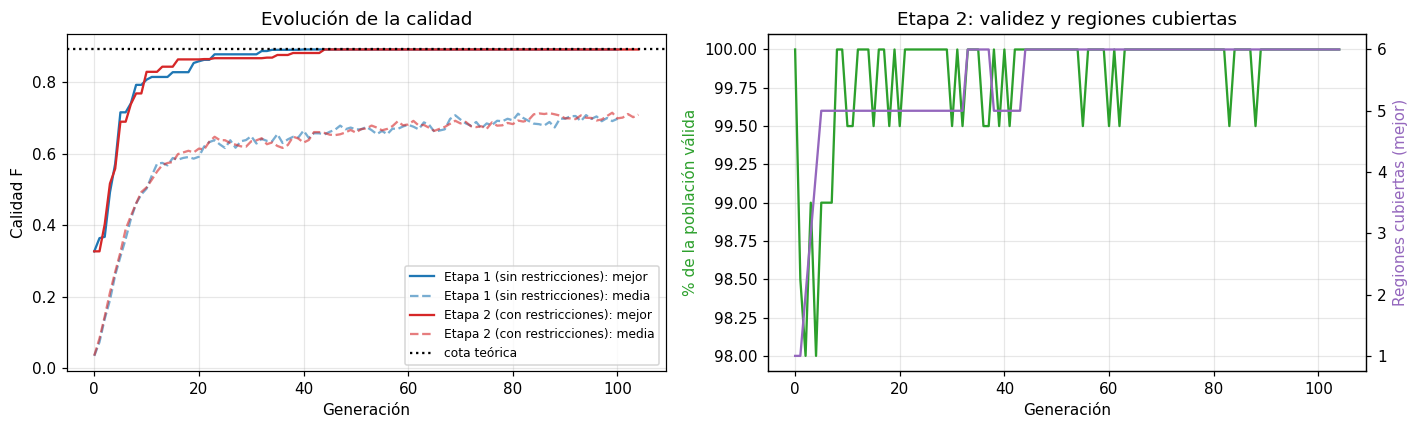

[OK] T2 Evolución: F pasó de 0.3270 a 0.8923 (+0.5653); 90 % del valor final en la generación 10; el mejor nunca empeoró=True


In [21]:
# ---------- T2. Evolución de la calidad
print("T2. EVOLUCIÓN")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for res, nom, col in [(res1, "Etapa 1 (sin restricciones)", "tab:blue"), (res2, "Etapa 2 (con restricciones)", "tab:red")]:
    h = res["hist"]
    ax[0].plot(h.gen, h.mejor_F, color=col, label=f"{nom}: mejor")
    ax[0].plot(h.gen, h.media_F, color=col, ls="--", alpha=.6, label=f"{nom}: media")
ax[0].axhline(cota, color="k", ls=":", label="cota teórica")
ax[0].set_xlabel("Generación"); ax[0].set_ylabel("Calidad F"); ax[0].set_title("Evolución de la calidad"); ax[0].legend(fontsize=8)
h = res2["hist"]
ax[1].plot(h.gen, h.frac_validas * 100, color="tab:green"); ax[1].set_ylabel("% de la población válida", color="tab:green")
ax2 = ax[1].twinx(); ax2.plot(h.gen, h.regiones_cubiertas, color="tab:purple"); ax2.set_ylabel("Regiones cubiertas (mejor)", color="tab:purple"); ax2.grid(False)
ax[1].set_xlabel("Generación"); ax[1].set_title("Etapa 2: validez y regiones cubiertas")
plt.tight_layout(); plt.show()
h = res2["hist"]
mejora = h.mejor_F.iloc[-1] - h.mejor_F.iloc[0]
gen90 = int(h.index[h.mejor_F >= 0.9 * h.mejor_F.iloc[-1]][0])
ok = h.mejor_F.is_monotonic_increasing
registrar("T2 Evolución", f"semilla {SEMILLA}", f"F pasó de {h.mejor_F.iloc[0]:.4f} a {h.mejor_F.iloc[-1]:.4f} (+{mejora:.4f}); 90 % del valor final en la generación {gen90}; el mejor nunca empeoró={ok}", ok and mejora > 0)

In [22]:
# ---------- T3 y T4. Zonas restringidas y posiciones ocupadas
print("T3 y T4. RESPETO A LAS RESTRICCIONES")
tm = margenes(res2, ESC_ETAPA2); display(tm.round(2))
ok_d = bool((tm[tm.Tipo == "desechos"]["¿Respetada?"] == "Sí").all()); ok_o = bool((tm[tm.Tipo == "ocupada"]["¿Respetada?"] == "Sí").all())
registrar("T3 Zonas de desechos", "3 zonas", f"margen mínimo = {tm[tm.Tipo=='desechos']['Margen (°)'].min():.2f}°", ok_d)
registrar("T4 Posiciones ocupadas", "2 objetos", f"margen mínimo = {tm[tm.Tipo=='ocupada']['Margen (°)'].min():.2f}°", ok_o)

# Prueba de que las restricciones tienen efecto real: la población inicial arranca TODA dentro de zonas prohibidas
print("\nPrueba adversaria: población inicial con todos los satélites dentro de zonas prohibidas")
rng = np.random.default_rng(SEMILLA); P0 = PARAMS.pob
pop_mala = np.zeros((P0, 8, 2))
for i in range(P0):
    for j in range(8):
        z = ESC_ETAPA2.zonas[rng.integers(len(ESC_ETAPA2.zonas))]
        la, lo = destino(z.lat, z.lon, rng.uniform(0, 360), z.radio_deg * np.sqrt(rng.uniform(0, 0.8)))
        pop_mala[i, j] = [la, lo]
assert (ev2.violacion_puntos(pop_mala).sum(-1) > 0).all()
res_adv = ejecutar_ga(ev2, PARAMS, SEMILLA, pob_inicial=pop_mala)
h = res_adv["hist"]
primera_valida = h.index[h.mejor_V == 0]
gen_val = int(primera_valida[0]) if len(primera_valida) else None
registrar("T3/T4 Prueba adversaria", "100 % de los individuos iniciales inválidos",
          f"violación inicial = {h.mejor_V.iloc[0]:.2f}; primera configuración válida en la generación {gen_val}; resultado final válido={res_adv['valida']}, F={res_adv['F']:.4f}",
          res_adv["valida"])

T3 y T4. RESPETO A LAS RESTRICCIONES


,Zona,Tipo,Radio (°),Distancia mínima de un satélite (°),Margen (°),¿Respetada?
0,Desechos Atlántico Norte,desechos,12.0,44.05,32.05,Sí
1,Desechos Pacífico Sur,desechos,10.0,53.05,43.05,Sí
2,Desechos Polar Norte,desechos,8.0,56.91,48.91,Sí
3,Objeto A,ocupada,5.0,42.30,37.30,Sí
4,Objeto B,ocupada,5.0,22.37,17.37,Sí


[OK] T3 Zonas de desechos: margen mínimo = 32.05°
[OK] T4 Posiciones ocupadas: margen mínimo = 17.37°

Prueba adversaria: población inicial con todos los satélites dentro de zonas prohibidas
[OK] T3/T4 Prueba adversaria: violación inicial = 1.95; primera configuración válida en la generación 3; resultado final válido=True, F=0.8923


In [23]:
# ---------- T5. Espacio reducido
print("T5. ESPACIO REDUCIDO")
EXTRA = (Zona("Extra 1", 30.0, -100.0, 12.0, "desechos"), Zona("Extra 2", 0.0, 20.0, 15.0, "desechos"),
         Zona("Extra 3", 30.0, 120.0, 10.0, "desechos"), Zona("Extra 4", -20.0, -70.0, 12.0, "desechos"),
         Zona("Extra 5", -35.0, 140.0, 12.0, "desechos"), Zona("Extra 6", 55.0, -120.0, 14.0, "desechos"))
ESC_REDUCIDO = replace(ESC_ETAPA2, zonas=ESC_ETAPA2.zonas + EXTRA)
fp0, fp1 = fraccion_prohibida(ESC_ETAPA2), fraccion_prohibida(ESC_REDUCIDO)
ev_red = Evaluador(ESC_REDUCIDO); res_red = ejecutar_ga(ev_red, PARAMS, SEMILLA)
print(f"Superficie prohibida: {100*fp0:.1f} % (etapa 2) → {100*fp1:.1f} % (reducido).")
display(tabla_regiones(res_red, ev_red).round(1))
cub_red = int((res_red["cov"] >= ESC_REDUCIDO.umbral_cubierta).sum())
registrar("T5 Espacio reducido", f"+6 zonas; superficie prohibida {100*fp0:.1f} % → {100*fp1:.1f} %",
          f"F={res_red['F']:.4f} (vs {res2['F']:.4f}); {cub_red}/6 cubiertas; válida={res_red['valida']}", res_red["valida"])
print("Interpretación:", "las restricciones adicionales no bajaron la calidad porque ninguna bloquea el alcance de las regiones." if res_red["F"] >= res2["F"] - 1e-3
      else f"la calidad bajó {res2['F']-res_red['F']:.4f} por las zonas adicionales.")

T5. ESPACIO REDUCIDO
Superficie prohibida: 2.7 % (etapa 2) → 10.0 % (reducido).


,Región,Prioridad,Cobertura (%),Doble cobertura (%),¿Cubierta?,Satélite más cercano (km),Satélites a ≤ radio del sensor
0,Península de Yucatán,Alta,100.0,100.0,Sí,642.3,2
1,Amazonía brasileña,Alta,100.0,100.0,Sí,479.0,2
2,California,Media,100.0,0.0,Sí,306.5,1
3,Sahel,Media,100.0,0.0,Sí,267.9,1
4,Japón,Media,100.0,0.0,Sí,641.0,1
5,Interior de Australia,Normal,100.0,0.0,Sí,460.4,1


[OK] T5 Espacio reducido: F=0.8923 (vs 0.8923); 6/6 cubiertas; válida=True
Interpretación: las restricciones adicionales no bajaron la calidad porque ninguna bloquea el alcance de las regiones.


In [24]:
# ---------- T6. Condición difícil o inviable
print("T6. CONDICIONES DIFÍCILES O INVIABLES")
# (a) Una zona prohibida cubre por completo el alcance de una región de prioridad alta
yuc = REGIONES[0]
ESC_BLOQ = replace(ESC_ETAPA2, zonas=ESC_ETAPA2.zonas + (Zona("Bloqueo sobre Yucatán", yuc.lat, yuc.lon, 14.0, "desechos"),))
ev_b = Evaluador(ESC_BLOQ); res_b = ejecutar_ga(ev_b, PARAMS, SEMILLA)
alc = {r.nombre: region_alcanzable(ev_b, r) for r in REGIONES}
display(tabla_regiones(res_b, ev_b).round(1))
inalc = [k for k, v in alc.items() if not v]
registrar("T6a Región bloqueada", "zona de 14° (≈1 558 km) centrada en Yucatán, mayor que el radio del sensor",
          f"regiones inalcanzables: {inalc}; F={res_b['F']:.4f}; válida={res_b['valida']}; Yucatán cubierta al {100*res_b['cov'][0]:.1f} %",
          res_b["valida"] and ("Península de Yucatán" in inalc) and res_b["cov"][0] < 0.95)
print("Interpretación: el sistema no inventa una solución imposible; entrega la mejor configuración válida y reporta la región como no cubierta.")

# (b) No existe ninguna posición válida
ESC_IMP = replace(ESC_ETAPA2, zonas=ESC_ETAPA2.zonas + (Zona("Zona global", 0.0, 0.0, 185.0, "desechos"),))
ev_i = Evaluador(ESC_IMP); res_i = ejecutar_ga(ev_i, ParamsGA(gens=40, paciencia=None), SEMILLA)
registrar("T6b Problema sin solución factible", "una zona prohibida cubre toda la esfera",
          f"válida={res_i['valida']}; violación mínima={res_i['V']:.3f} → el sistema marca la solución como INVIÁLIDA", not res_i["valida"])

T6. CONDICIONES DIFÍCILES O INVIABLES


,Región,Prioridad,Cobertura (%),Doble cobertura (%),¿Cubierta?,Satélite más cercano (km),Satélites a ≤ radio del sensor
0,Península de Yucatán,Alta,0.0,0.0,No,3784.5,0
1,Amazonía brasileña,Alta,100.0,100.0,Sí,226.2,2
2,California,Media,100.0,0.0,Sí,336.6,1
3,Sahel,Media,100.0,100.0,Sí,598.2,2
4,Japón,Media,100.0,100.0,Sí,562.7,2
5,Interior de Australia,Normal,100.0,0.0,Sí,697.8,1


[OK] T6a Región bloqueada: regiones inalcanzables: ['Península de Yucatán']; F=0.7231; válida=True; Yucatán cubierta al 0.0 %
Interpretación: el sistema no inventa una solución imposible; entrega la mejor configuración válida y reporta la región como no cubierta.
[OK] T6b Problema sin solución factible: válida=False; violación mínima=0.237 → el sistema marca la solución como INVIÁLIDA


T7. VARIACIÓN ENTRE EJECUCIONES (20 semillas, mismas condiciones)


,semilla,F,regiones_cubiertas,generaciones
mean,2135.5000,0.8908,5.9500,108.6000
std,5.9161,0.0069,0.2236,24.2322
min,2126.0000,0.8615,5.0000,79.0000
max,2145.0000,0.8923,6.0000,163.0000


Corridas válidas: 20/20 | corridas con las 6 regiones cubiertas: 19/20
Ejecuciones que NO cubrieron las 6 regiones (convergencia prematura): [{'semilla': 2134, 'F': 0.8615, 'regiones_cubiertas': 5}]


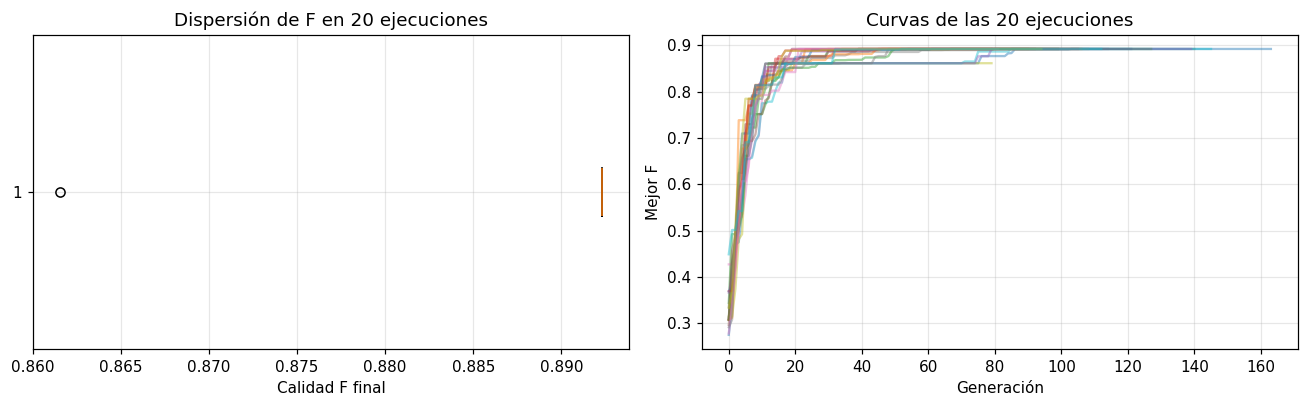

Distancia media entre configuraciones de ejecuciones distintas (emparejando satélites): 783 km
[OK] T7 Variación entre ejecuciones: F media=0.8908 ± 0.0069 (mín 0.8615, máx 0.8923); distancia media entre configuraciones=783 km
Interpretación: calidades similares con posiciones distintas indican que existen muchas configuraciones equivalentes (por ejemplo, los satélites sobrantes pueden ir en varios sitios).


In [25]:
# ---------- T7. Variación entre ejecuciones
print("T7. VARIACIÓN ENTRE EJECUCIONES (20 semillas, mismas condiciones)")
N_RUNS = 20
corridas = [ejecutar_ga(ev2, PARAMS, SEMILLA_BASE + 100 + k) for k in range(N_RUNS)]
dfv = pd.DataFrame({"semilla": [r["seed"] for r in corridas], "F": [r["F"] for r in corridas],
                    "regiones_cubiertas": [int((r["cov"] >= ESC_ETAPA2.umbral_cubierta).sum()) for r in corridas],
                    "valida": [r["valida"] for r in corridas], "generaciones": [r["gens_ejecutadas"] for r in corridas]})
display(dfv.describe().round(4).loc[["mean", "std", "min", "max"]])
print(f"Corridas válidas: {int(dfv.valida.sum())}/{N_RUNS} | corridas con las 6 regiones cubiertas: {int((dfv.regiones_cubiertas==6).sum())}/{N_RUNS}")
fallidas = dfv[dfv.regiones_cubiertas < 6]
if len(fallidas):
    print("Ejecuciones que NO cubrieron las 6 regiones (convergencia prematura):", fallidas[["semilla", "F", "regiones_cubiertas"]].round(4).to_dict("records"))
corridas1 = [ejecutar_ga(ev1, PARAMS, SEMILLA_BASE + 100 + k) for k in range(N_RUNS)]      # misma prueba sin restricciones (para el análisis 4)
F1 = np.array([r["F"] for r in corridas1])

D = np.array([[dist_entre_configs(a["config"], b["config"]) if a is not b else 0 for b in corridas] for a in corridas])
dm = D[np.triu_indices(N_RUNS, 1)].mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].boxplot(dfv.F, vert=False); ax[0].set_xlabel("Calidad F final"); ax[0].set_title("Dispersión de F en 20 ejecuciones")
for r in corridas: ax[1].plot(r["hist"].gen, r["hist"].mejor_F, alpha=.45)
ax[1].set_xlabel("Generación"); ax[1].set_ylabel("Mejor F"); ax[1].set_title("Curvas de las 20 ejecuciones")
plt.tight_layout(); plt.show()
print(f"Distancia media entre configuraciones de ejecuciones distintas (emparejando satélites): {dm:,.0f} km")
registrar("T7 Variación entre ejecuciones", f"{N_RUNS} semillas, params por defecto",
          f"F media={dfv.F.mean():.4f} ± {dfv.F.std():.4f} (mín {dfv.F.min():.4f}, máx {dfv.F.max():.4f}); distancia media entre configuraciones={dm:,.0f} km",
          bool(dfv.valida.all()))
print("Interpretación: calidades similares con posiciones distintas indican que existen muchas configuraciones equivalentes (por ejemplo, los satélites sobrantes pueden ir en varios sitios).")

In [26]:
# ---------- Prueba propia A: sensibilidad al radio del sensor (supuesto clave del modelo)
print("PRUEBA PROPIA A. SENSIBILIDAD AL RADIO DEL SENSOR (5 semillas por valor)")
filas = []
for rs in [400, 600, 800, 1000, 1500, 2000]:
    esc_k = replace(ESC_ETAPA2, radio_sensor_km=rs); ev_k = Evaluador(esc_k)
    rr = [ejecutar_ga(ev_k, PARAMS, SEMILLA_BASE + 300 + s) for s in range(5)]
    filas.append({"Radio sensor (km)": rs, "F media": np.mean([x["F"] for x in rr]), "F desv.": np.std([x["F"] for x in rr]),
                  "Regiones cubiertas (media)": np.mean([(x["cov"] >= .95).sum() for x in rr]), "Cota teórica": cota_superior(esc_k),
                  "Cota válida (sep. > 2(Rs+300))": separacion_minima_regiones_km(esc_k) > 2 * (rs + 300)})
dfs = pd.DataFrame(filas); display(dfs.round(4))
registrar("Propia A Sensibilidad al radio del sensor", "radios 400–2000 km", f"F media va de {dfs['F media'].min():.3f} a {dfs['F media'].max():.3f}",
          bool((dfs['F media'] > 0).all()))
print("Interpretación: cuando la última columna es False, un mismo satélite puede cubrir parte de dos regiones, la cota teórica deja de valer y F puede superarla.")

PRUEBA PROPIA A. SENSIBILIDAD AL RADIO DEL SENSOR (5 semillas por valor)


,Radio sensor (km),F media,F desv.,Regiones cubiertas (media),Cota teórica,Cota válida (sep. > 2(Rs+300))
0,400,0.8798,0.0149,5.6,0.8923,True
1,600,0.8677,0.0123,5.2,0.8923,True
2,800,0.8862,0.0123,5.8,0.8923,True
3,1000,0.8923,0.0000,6.0,0.8923,True
4,1500,0.8923,0.0000,6.0,0.8923,False
5,2000,0.9515,0.0004,6.0,0.8923,False


[OK] Propia A Sensibilidad al radio del sensor: F media va de 0.868 a 0.951
Interpretación: cuando la última columna es False, un mismo satélite puede cubrir parte de dos regiones, la cota teórica deja de valer y F puede superarla.


In [27]:
# ---------- Prueba propia B: ¿el algoritmo evolutivo es mejor que buscar al azar con el mismo presupuesto?
print("PRUEBA PROPIA B. ALGORITMO EVOLUTIVO VS BÚSQUEDA ALEATORIA (misma cantidad de evaluaciones)")
presupuesto = corridas[0]["evaluaciones"]
aleat = [busqueda_aleatoria(ev2, presupuesto, SEMILLA_BASE + 500 + k) for k in range(N_RUNS)]
Fa = np.array([a["F"] for a in aleat]); Fg = dfv.F.values
U, pval = stats.mannwhitneyu(Fg, Fa, alternative="greater")
display(pd.DataFrame({"Método": ["Evolutivo", "Búsqueda aleatoria"], "F media": [Fg.mean(), Fa.mean()], "F desv.": [Fg.std(), Fa.std()],
                      "F máx.": [Fg.max(), Fa.max()], "Evaluaciones": [presupuesto, presupuesto]}).round(4))
print(f"Prueba de Mann-Whitney (evolutivo > aleatorio): U={U:.0f}, p={pval:.2e}")
registrar("Propia B Evolutivo vs aleatorio", f"{presupuesto:,} evaluaciones por ejecución, {N_RUNS} semillas",
          f"F evolutivo={Fg.mean():.4f} vs aleatorio={Fa.mean():.4f}; p={pval:.2e}", pval < 0.05)

PRUEBA PROPIA B. ALGORITMO EVOLUTIVO VS BÚSQUEDA ALEATORIA (misma cantidad de evaluaciones)


,Método,F media,F desv.,F máx.,Evaluaciones
0,Evolutivo,0.8908,0.0067,0.8923,32148
1,Búsqueda aleatoria,0.5040,0.0320,0.5744,32148


Prueba de Mann-Whitney (evolutivo > aleatorio): U=400, p=5.10e-09
[OK] Propia B Evolutivo vs aleatorio: F evolutivo=0.8908 vs aleatorio=0.5040; p=5.10e-09


In [28]:
# ---------- Prueba propia C: justificación de los parámetros por defecto
print("PRUEBA PROPIA C. ¿POR QUÉ ESTOS PARÁMETROS? (20 semillas por configuración)")
configs = {"Población 120, reubicación 0.03": ParamsGA(pob=120, p_reset=0.03),
           "Población 120, reubicación 0.08": ParamsGA(pob=120, p_reset=0.08),
           "Por defecto: población 200, reubicación 0.05": PARAMS}
filas = []
for nombre, pp in configs.items():
    rr = [ejecutar_ga(ev2, pp, SEMILLA_BASE + 700 + k) for k in range(20)]
    filas.append({"Configuración": nombre, "Ejecuciones con 6/6 regiones": sum(int((x["cov"] >= .95).sum() == 6) for x in rr),
                  "F media": np.mean([x["F"] for x in rr]), "F mínima": np.min([x["F"] for x in rr]), "Evaluaciones medias": np.mean([x["evaluaciones"] for x in rr])})
dfp = pd.DataFrame(filas); display(dfp.round(4))
registrar("Propia C Justificación de parámetros", "3 configuraciones × 20 semillas",
          "; ".join(f"{r['Configuración']}: {r['Ejecuciones con 6/6 regiones']}/20" for _, r in dfp.iterrows()),
          bool(dfp.iloc[2]["Ejecuciones con 6/6 regiones"] >= dfp["Ejecuciones con 6/6 regiones"].max()))
print("Interpretación: los parámetros por defecto se eligieron porque, con mayor población y más reubicaciones aleatorias, el algoritmo cae menos en el óptimo local de 'duplicar una región en lugar de cubrir la de menor prioridad'.")

PRUEBA PROPIA C. ¿POR QUÉ ESTOS PARÁMETROS? (20 semillas por configuración)


,Configuración,Ejecuciones con 6/6 regiones,F media,F mínima,Evaluaciones medias
0,"Población 120, reubicación 0.03",18,0.8892,0.8615,12392.8
1,"Población 120, reubicación 0.08",18,0.8892,0.8615,15524.8
2,"Por defecto: población 200, reubicación 0.05",20,0.8923,0.8923,23465.2


[OK] Propia C Justificación de parámetros: Población 120, reubicación 0.03: 18/20; Población 120, reubicación 0.08: 18/20; Por defecto: población 200, reubicación 0.05: 20/20
Interpretación: los parámetros por defecto se eligieron porque, con mayor población y más reubicaciones aleatorias, el algoritmo cae menos en el óptimo local de 'duplicar una región en lugar de cubrir la de menor prioridad'.


## 5. Cambio en las condiciones (sección 3.3)

La función `reevaluar` responde dos preguntas con la configuración anterior: ¿sigue siendo **válida** y cuánto vale ahora? Luego `reoptimizar` arranca el algoritmo desde esa configuración y mide cuánto tuvo que cambiar.

In [29]:
base = res2["config"]
idx_japon = int(np.argmin(dist_km(base[:, 0], base[:, 1], REGIONES[4].lat, REGIONES[4].lon)))   # satélite que atiende a Japón
cambios = {
    "A. Se libera la zona Atlántico Norte": replace(ESC_ETAPA2, zonas=tuple(z for z in ESC_ETAPA2.zonas if z.nombre != "Desechos Atlántico Norte")),
    "B. Cambian prioridades (Australia → Alta, Yucatán → Normal)": replace(ESC_ETAPA2, regiones=(
        replace(REGIONES[0], prioridad="Normal"),) + REGIONES[1:5] + (replace(REGIONES[5], prioridad="Alta"),)),
    f"C. Nueva zona de desechos de 8° sobre el satélite S{idx_japon+1} (el de Japón)": replace(
        ESC_ETAPA2, zonas=ESC_ETAPA2.zonas + (Zona("Zona nueva", float(base[idx_japon, 0]), float(base[idx_japon, 1]), 8.0, "desechos"),)),
}

filas = []
for nombre, esc_n in cambios.items():
    r0 = reevaluar(esc_n, base)
    ev_n, r1 = reoptimizar(esc_n, base, SEMILLA, PARAMS)
    movidos = int((dist_km(r1["config"][:, None, 0], r1["config"][:, None, 1], base[None, :, 0], base[None, :, 1]).min(1) > 100).sum())
    filas.append({"Cambio": nombre, "Config. anterior válida": r0["valida"], "F anterior (condiciones nuevas)": r0["F"],
                  "F reoptimizada": r1["F"], "¿Reoptimizada válida?": r1["valida"], "Satélites que se movieron > 100 km": movidos})
dfc = pd.DataFrame(filas); display(dfc.round(4))
print("Nota: el algoritmo no penaliza mover satélites, por eso al reoptimizar mueve más de los necesarios. Agregar un costo de reubicación a la calidad sería una mejora.")
for _, f in dfc.iterrows():
    registrar("Cambio: " + f["Cambio"][:48], "re-evaluación y reoptimización",
              f"anterior válida={f['Config. anterior válida']}, F {f['F anterior (condiciones nuevas)']:.4f} → {f['F reoptimizada']:.4f}; movidos={f['Satélites que se movieron > 100 km']}",
              bool(f["¿Reoptimizada válida?"]))

,Cambio,Config. anterior válida,F anterior (condiciones nuevas),F reoptimizada,¿Reoptimizada válida?,Satélites que se movieron > 100 km
0,A. Se libera la zona Atlántico Norte,True,0.8923,0.8923,True,0
1,"B. Cambian prioridades (Australia → Alta, Yuca...",True,0.8615,0.8923,True,7
2,C. Nueva zona de desechos de 8° sobre el satél...,False,0.8923,0.8923,True,7


Nota: el algoritmo no penaliza mover satélites, por eso al reoptimizar mueve más de los necesarios. Agregar un costo de reubicación a la calidad sería una mejora.
[OK] Cambio: A. Se libera la zona Atlántico Norte: anterior válida=True, F 0.8923 → 0.8923; movidos=0
[OK] Cambio: B. Cambian prioridades (Australia → Alta, Yucatá: anterior válida=True, F 0.8615 → 0.8923; movidos=7
[OK] Cambio: C. Nueva zona de desechos de 8° sobre el satélit: anterior válida=False, F 0.8923 → 0.8923; movidos=7


## 6. Análisis de resultados (Entregable 4)

La celda siguiente reúne los números reales de **tu** ejecución para responder las siete preguntas del enunciado. Úsala como base y redacta la interpretación con tus palabras en el documento.

In [30]:
tr = tabla_regiones(res2, ev2)
print("1. ¿Qué tan bien se observan las regiones solicitadas?")
print(f"   {int((tr['¿Cubierta?']=='Sí').sum())}/6 regiones cubiertas; cobertura ponderada F = {res2['F']:.4f}; cobertura mínima = {tr['Cobertura (%)'].min():.1f} %.")
print("2. ¿Cómo cambió la calidad durante la evolución?")
h = res2["hist"]
print(f"   De {h.mejor_F.iloc[0]:.4f} (mejor de la población inicial) a {h.mejor_F.iloc[-1]:.4f} en {res2['gens_ejecutadas']} generaciones; parada por: {res2['parada']}.")
print("3. ¿Qué diferencias hubo entre ejecuciones?")
print(f"   F media {dfv.F.mean():.4f} ± {dfv.F.std():.4f} (rango {dfv.F.min():.4f}–{dfv.F.max():.4f}); las configuraciones difieren en promedio {dm:,.0f} km entre sí.")
print("4. ¿Qué efecto tuvieron las restricciones?")
U4, p4 = stats.mannwhitneyu(F1, dfv.F.values, alternative="two-sided")
print(f"   20 ejecuciones sin restricciones: F = {F1.mean():.4f} ± {F1.std():.4f}; con restricciones: F = {dfv.F.mean():.4f} ± {dfv.F.std():.4f} (Mann-Whitney bilateral p = {p4:.2f}).")
print("   " + ("No hay diferencia estadística: con las posiciones del enunciado ninguna zona queda sobre las regiones, así que las restricciones no reducen el máximo alcanzable." if p4 > 0.05
               else "Hay diferencia estadística entre ambas condiciones."))
print("   Aun así sí condicionan la búsqueda: se verificó que se respetan (T3, T4) y que obligan a corregir una población inicial inválida (prueba adversaria).")
print("5. ¿Qué pasa cuando no se pueden satisfacer todas las condiciones?")
print(f"   Con el bloqueo sobre Yucatán la calidad baja a {res_b['F']:.4f} y esa región queda al {100*res_b['cov'][0]:.1f} %; si no existe posición válida, la solución se marca inválida (T6).")
print("6. ¿Qué limitaciones tiene el criterio de evaluación?")
print("   Cobertura circular y estática, sin tiempos de revisita; el peso de la doble cobertura (0.2) y el radio del sensor son supuestos; la prueba propia A muestra que el resultado depende del radio del sensor.")
print("7. ¿Qué evidencia permite afirmar que una solución es mejor que otra?")
print(f"   Misma métrica y mismas condiciones; el evolutivo supera a la búsqueda aleatoria con igual presupuesto (p={pval:.1e}); y se compara contra la cota teórica ({100*res2['F']/cota:.1f} % alcanzado).")
# Veredicto de 'suficientemente buena'
crit = {"válida": res2["valida"], "todas las regiones alcanzables cubiertas": all(c >= .95 for c, r in zip(res2["cov"], REGIONES) if region_alcanzable(ev2, r)),
        "F ≥ 95 % de la cota": res2["F"] >= 0.95 * cota}
print("\nCriterio de 'solución suficientemente buena':", crit, "→", "CUMPLE" if all(crit.values()) else "NO CUMPLE")

1. ¿Qué tan bien se observan las regiones solicitadas?
   6/6 regiones cubiertas; cobertura ponderada F = 0.8923; cobertura mínima = 100.0 %.
2. ¿Cómo cambió la calidad durante la evolución?
   De 0.3270 (mejor de la población inicial) a 0.8923 en 104 generaciones; parada por: sin mejora durante 60 generaciones.
3. ¿Qué diferencias hubo entre ejecuciones?
   F media 0.8908 ± 0.0069 (rango 0.8615–0.8923); las configuraciones difieren en promedio 783 km entre sí.
4. ¿Qué efecto tuvieron las restricciones?
   20 ejecuciones sin restricciones: F = 0.8908 ± 0.0067; con restricciones: F = 0.8908 ± 0.0069 (Mann-Whitney bilateral p = 1.00).
   No hay diferencia estadística: con las posiciones del enunciado ninguna zona queda sobre las regiones, así que las restricciones no reducen el máximo alcanzable.
   Aun así sí condicionan la búsqueda: se verificó que se respetan (T3, T4) y que obligan a corregir una población inicial inválida (prueba adversaria).
5. ¿Qué pasa cuando no se pueden satisfac

## 7. Centro de mando 2D y 3D (Entregable 5)

El visor es un **centro de mando con estética Cyberpunk 2077**: mapa táctico en rojo y cian, hologramas, marcadores hexagonales, zonas restringidas con franjas de peligro y HUD con panel del satélite activo. Funciona **sin librerías externas** y con los datos reales de la ejecución.

- **2D / 3D:** pestañas superiores o teclas `2` y `3`.
- **Satélites:** modelo con paneles solares, antena y huella de visión (el radio que abarcan). En 3D también se dibuja el **cono de cobertura** desde el satélite hasta el suelo y el cascarón orbital de 800 km.
- **Panel derecho:** satélite activo (latitud/longitud, altitud, radio de huella, área, elevación mínima equivalente, proximidad a zonas restringidas y regiones en rango) y estado de las regiones críticas.
- **Panel izquierdo:** modo 2D/3D, **vistas de cámara** (órbita libre, polos, cinturón ecuatorial, seguir satélite) y **capas holográficas** que se encienden y apagan.
- **Evolución:** el botón *Evolución* (o la barra espaciadora) reproduce cómo se movió la mejor constelación generación por generación. El botón *Inicial* superpone la configuración de la generación 0.
- **Escenarios:** etapa 2, etapa 1, bloqueo sobre Yucatán y espacio reducido.
- **Teclas:** `1`–`8` elige satélite, `←` `→` cambia de generación, `H` oculta el HUD, `L` abre la leyenda.



In [31]:
ESCENARIOS_VISOR = [("Etapa 2 · con restricciones", ESC_ETAPA2, res2),
                    ("Etapa 1 · sin restricciones", ESC_ETAPA1, res1),
                    ("Prueba T6a · bloqueo sobre Yucatán", ESC_BLOQ, res_b),
                    ("Prueba T5 · espacio reducido", ESC_REDUCIDO, res_red)]
doc = guardar_visor(ESCENARIOS_VISOR, "resultados/astroshield_visor.html")
display(HTML(iframe_html(doc, 820)))
print("Visor guardado en resultados/astroshield_visor.html (%d KB)" % (len(doc) // 1024))

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Visor guardado en resultados/astroshield_visor.html (188 KB)


## 8. Exportar resultados para el repositorio (Entregable 6)

In [34]:
pd.DataFrame(RESUMEN).to_csv("resultados/resumen_pruebas.csv", index=False)
res2["hist"].to_csv("resultados/historial_etapa2.csv", index=False)
dfv.to_csv("resultados/variacion_20_ejecuciones.csv", index=False)
tabla_regiones(res2, ev2).to_csv("resultados/cobertura_regiones_etapa2.csv", index=False)
tabla_satelites(res2).to_csv("resultados/configuracion_final.csv", index=False)
pd.DataFrame(res2["inicial"], columns=["lat", "lon"]).to_csv("resultados/configuracion_inicial.csv", index=False)
with open("resultados/parametros.json", "w", encoding="utf-8") as f:
    json.dump({"semilla": SEMILLA, "radio_sensor_km": ESC_ETAPA2.radio_sensor_km, "radio_region_km": ESC_ETAPA2.radio_region_km,
               "pesos": ESC_ETAPA2.pesos, "peso_redundancia": ESC_ETAPA2.peso_redundancia, "umbral_cubierta": ESC_ETAPA2.umbral_cubierta,
               "ga": PARAMS.__dict__}, f, ensure_ascii=False, indent=2)
shutil.make_archive("resultados_astroshield", "zip", "resultados")
print(pd.DataFrame(RESUMEN)[["Prueba", "Estado"]].to_string(index=False))

                                                  Prueba Estado
                          T1 Escenario inicial (etapa 1)     OK
                T1 Escenario con restricciones (etapa 2)     OK
                                            T2 Evolución     OK
                                    T3 Zonas de desechos     OK
                                  T4 Posiciones ocupadas     OK
                                 T3/T4 Prueba adversaria     OK
                                     T5 Espacio reducido     OK
                                    T6a Región bloqueada     OK
                      T6b Problema sin solución factible     OK
                          T7 Variación entre ejecuciones     OK
               Propia A Sensibilidad al radio del sensor     OK
                         Propia B Evolutivo vs aleatorio     OK
                    Propia C Justificación de parámetros     OK
            Cambio: A. Se libera la zona Atlántico Norte     OK
Cambio: B. Cambian prioridades (Australi